# Do Leaders Matter for Growth?
## Leader backgrounds, executive constraints and GDP growth — regression notebook

**BU3104 · Personnel Economics and Finance · End-semester presentation**  
Lakshay Aggarwal · Avishkar Rawal · Nikita

This notebook produces **every regression table, test and figure** in the end-semester deck. It reads only the two canonical files built for the mid-semester analysis:

- `Leaders_canonical_country_year.csv` — one row per country-year (leader in office, LEAD traits, Archigos entry/exit, Polity IV, WDI growth)
- `Leaders_canonical_spell.csv` — one row per leadership spell

**Research questions**

- **RQ1 — Do leaders matter for growth?** Leader fixed effects against a placebo benchmark (Table 2).
- **RQ2 — Do leader backgrounds matter?** Education, military service, combat, a rebel past and irregular entry in Eq. 1 (Tables 3 and 6).
- **RQ3 — Does an institutional void amplify the effect of backgrounds?** Trait × void interactions (Table 4), with development as the alternative moderator (Table 5).

Run it top to bottom. Nothing is typed in by hand: all numbers in the slides come from `outputs/results.json`, written by the last cell.

**Contents**

1. Estimation engine and its validation against statsmodels
2. Data construction and cleaning
3. Table 1 — Summary statistics, and exploratory data analysis (3.1)
4. Table 2 — Do leaders matter? Leader fixed effects and a placebo benchmark
5. Table 3 — The main equation (Eq. 1), built up column by column
6. Table 4 — Heterogeneity I: institutional void vs institutional support (Eq. 2)
7. Table 5 — Heterogeneity II: development and state capacity (Eq. 3)
8. Table 6 — Heterogeneity III: how power was taken, complementarities, era (Eq. 4)
9. Table 7 — Reverse causality: Granger tests in both directions and lead tests
10. Table 8 — Robustness
11. Table 9 — A second outcome: growth volatility
12. Export for the slides

### Conventions used throughout

| Item | Choice | Why |
|---|---|---|
| Unit of observation | Country *c* in year *t*, matched to the leader in office for most of the year | Growth is measured annually; leaders change at irregular dates |
| Outcome | Real GDP growth, % (WDI), winsorised at the 1st/99th percentiles | Comparable with Jones & Olken (2005) and Besley et al. (2011); winsorising stops a handful of war or oil years from driving estimates |
| Estimator | OLS with country and year fixed effects (two-way fixed effects) | Compares leaders **within** the same country, net of world-wide shocks |
| Standard errors | Clustered by country (CR1), small-sample factor G/(G−1)·(N−1)/(N−K) | Growth is serially correlated within a country; clustering keeps inference honest |
| p-values | Student-t with G−1 degrees of freedom (Stata convention) | Slightly more conservative than the normal approximation |
| Stars | \* p<0.10, \*\* p<0.05, \*\*\* p<0.01 | Standard in economics journals |
| Intercept β₀ | Fixed-effect dummies are centred (the `areg`/`reghdfe` convention) and continuous controls are measured as deviations from their sample means | Slopes are unchanged, and β₀ gets an economic meaning: predicted growth under the reference leader (civilian, no graduate degree, no rebel past, regular entry) at average age, experience, income, lagged growth and constraints, in an average country-year |

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, HTML

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 200)

DATA_CY    = "Leaders_canonical_country_year.csv"
DATA_SPELL = "Leaders_canonical_spell.csv"
DATA_P5    = "p5v2018.xls"           # Polity5 annual time series, Center for Systemic Peace (1776–2018)
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
SEED = 2026

BLUE, ORANGE, GREY, INK, LIGHT = "#0B3F94", "#E8712C", "#8A8F98", "#111111", "#D9DCE3"
from matplotlib import font_manager
_avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Poppins", "Helvetica Neue", "Arial", "DejaVu Sans"] if f in _avail), "DejaVu Sans")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": [FONT, "DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11})
RESULTS = {}          # every number used in the slides is stored here and exported at the end
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


## 1. Estimation engine

We estimate every model with one small, transparent function rather than a black box. It does exactly what Stata's `reg y x i.country i.year, cluster(country)` and statsmodels' `ols(...).fit(cov_type="cluster")` do:

$$\hat\beta = (Z'Z)^{-1}Z'y$$

$$\hat{V}_{CR1} = \frac{G}{G-1}\,\frac{N-1}{N-K}\,(Z'Z)^{-1}\left(\sum_{g=1}^{G} Z_g'\hat{u}_g\hat{u}_g'Z_g\right)(Z'Z)^{-1}$$

*Z* stacks a constant, the regressors and the fixed-effect dummies; *g* indexes countries (clusters); *K* is the number of estimated parameters. Writing it ourselves also lets us (i) report the intercept β₀ under a clear convention, and (ii) run hundreds of leader-fixed-effect regressions quickly for the placebo test in Section 4.

In [2]:
class FEResult:
    pass

def fe_ols(df, y, X, fe=("country_id", "year"), cluster="country_id", pvalue_dist="t"):
    # OLS of y on X plus fixed-effect dummies; cluster-robust (CR1) standard errors.
    X = list(X)
    cols = list(dict.fromkeys([y] + X + list(fe) + ([cluster] if cluster else [])))
    d = df[cols].dropna().copy()
    n = len(d); yv = d[y].to_numpy(float)
    blocks, names = [np.ones((n, 1)), d[X].to_numpy(float)], ["const"] + X
    for f in fe:
        D = pd.get_dummies(d[f].astype(str), drop_first=True, dtype=float).to_numpy()
        if D.shape[1]:
            blocks.append(D - D.mean(axis=0))      # centred dummies -> beta0 = ybar - xbar'b
    Z = np.hstack(blocks)
    ZtZ_inv = np.linalg.pinv(Z.T @ Z)
    b = ZtZ_inv @ (Z.T @ yv); u = yv - Z @ b
    K = int(np.linalg.matrix_rank(Z)); p = 1 + len(X)
    r = FEResult(); r.y, r.X, r.fe, r.nobs, r.K = y, X, tuple(fe), n, K
    r.rss = float(u @ u); r.tss = float(((yv - yv.mean()) ** 2).sum())
    r.r2 = 1 - r.rss / r.tss; r.r2_adj = 1 - (1 - r.r2) * (n - 1) / (n - K)
    if cluster:
        codes, uniq = pd.factorize(d[cluster]); G = len(uniq)
        agg = np.zeros((G, Z.shape[1])); np.add.at(agg, codes, Z * u[:, None])
        V = (G / (G - 1)) * ((n - 1) / (n - K)) * ZtZ_inv @ (agg.T @ agg) @ ZtZ_inv
        r.G, r.df_t = G, G - 1
    else:
        V = (r.rss / (n - K)) * ZtZ_inv; r.G, r.df_t = None, n - K
    r.params = pd.Series(b[:p], index=names)
    r.cov = pd.DataFrame(V[:p, :p], index=names, columns=names)
    r.bse = pd.Series(np.sqrt(np.clip(np.diag(V[:p, :p]), 0, None)), index=names)
    r.tvalues = r.params / r.bse
    dist = stats.t(r.df_t) if pvalue_dist == "t" else stats.norm()
    r.pvalues = pd.Series(2 * dist.sf(np.abs(r.tvalues)), index=names)
    r.data, r.resid = d, pd.Series(u, index=d.index)
    return r

def wald_test(r, names):
    # Joint test that all coefficients in `names` equal zero: F(q, G-1).
    names = list(names); b = r.params[names].to_numpy(); V = r.cov.loc[names, names].to_numpy()
    F = float(b @ np.linalg.pinv(V) @ b) / len(names)
    return F, float(stats.f.sf(F, len(names), r.df_t))

def lincom(r, w):
    # Linear combination sum_k w_k * b_k with its standard error (e.g. a marginal effect beta + delta).
    names = list(w); a = np.array([w[k] for k in names], float)
    est = float(a @ r.params[names].to_numpy()); se = float(np.sqrt(a @ r.cov.loc[names, names].to_numpy() @ a))
    return est, se, float(2 * stats.t.sf(abs(est / se), r.df_t))

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def within_r2(r):
    # Share of the variation left after the fixed effects that the regressors explain.
    base = fe_ols(r.data, r.y, [], r.fe, cluster=None)
    return 1 - r.rss / base.rss

def num(x, d=3):
    s = f"{x:.{d}f}"
    return s.replace("-", "\u2212")

def reg_table(cols, rows, labels, extra=None, title="", note="", digits=3):
    # Economics-style table: coefficient with stars, standard error underneath; returns HTML and a dict.
    head = "".join(f"<th>{c}</th>" for c in cols)
    body, rec = [], {c: {} for c in cols}
    for v in rows:
        c1, c2 = [], []
        for c, r in cols.items():
            if r is not None and v in r.params.index:
                b, se, p = r.params[v], r.bse[v], r.pvalues[v]
                c1.append(f"{num(b, digits)}{stars(p)}"); c2.append(f"({se:.{digits}f})")
                rec[c][v] = {"b": float(b), "se": float(se), "p": float(p)}
            else:
                c1.append(""); c2.append("")
        body.append(f"<tr><td class='lab'>{labels.get(v, v)}</td>" + "".join(f"<td>{x}</td>" for x in c1) + "</tr>")
        body.append("<tr class='se'><td></td>" + "".join(f"<td>{x}</td>" for x in c2) + "</tr>")
    sep = True
    for lab, vals in (extra or []):
        cls = " class='first'" if sep else ""; sep = False
        body.append(f"<tr{cls}><td class='lab'>{lab}</td>" + "".join(f"<td>{x}</td>" for x in vals) + "</tr>")
    html = (f"<div class='tabtitle'>{title}</div><table class='regtab'><thead><tr><th></th>{head}</tr></thead>"
            f"<tbody>{''.join(body)}</tbody></table><div class='tabnote'>{note}</div>")
    return html, rec

TABLE_CSS = '''<style>
.tabtitle{font-weight:700;font-size:14px;margin:10px 0 4px}
table.regtab{border-collapse:collapse;font-family:Georgia,serif;font-size:13px}
table.regtab th{border-top:2px solid #111;border-bottom:1px solid #111;padding:4px 12px;text-align:center}
table.regtab td{padding:2px 12px;text-align:center}
table.regtab td.lab{text-align:left}
table.regtab tr.se td{color:#555;font-size:12px;padding-bottom:5px}
table.regtab tr.first td{border-top:1px solid #111}
table.regtab tbody tr:last-child td{border-bottom:2px solid #111}
.tabnote{font-size:11.5px;color:#444;max-width:980px;margin-top:4px}
</style>'''
display(HTML(TABLE_CSS))
print("Estimation engine loaded.")

Estimation engine loaded.


### 1.1 Validation: the engine reproduces statsmodels exactly

Before using the engine, we re-estimate **Model D1 from `leaders_eda.ipynb`** — same data, same sample rule, same specification — and compare it with the statsmodels output stored in that notebook. (statsmodels reports normal-approximation p-values, so we switch to the normal for this check only.) If statsmodels is installed in your kernel, the cell also re-runs it live.

In [3]:
eda = pd.read_csv(DATA_CY, low_memory=False)
for c in eda.columns:                      # the EDA notebook's own cleaning rule
    if eda[c].dtype in [np.int64, np.float64]:
        eda[c] = eda[c].replace(-77, np.nan)
d1_vars = ["grad_edu", "milservice", "age", "yrsexper", "irregular_entry", "lag_gdp_growth", "lag_log_gdp_pc"]
d1 = eda.dropna(subset=["gdp_growth_winsor", "grad_edu", "milservice", "age", "yrsexper", "lag_gdp_growth", "lag_log_gdp_pc"])
m = fe_ols(d1, "gdp_growth_winsor", d1_vars, fe=("idacr", "year"), cluster="idacr", pvalue_dist="normal")

stored = {  # printed by statsmodels in leaders_eda.ipynb, cell 18
    "grad_edu": (0.0675, 0.1344), "milservice": (0.2625, 0.1650), "age": (0.0129, 0.0080),
    "yrsexper": (-0.0060, 0.0076), "irregular_entry": (-0.7099, 0.3025),
    "lag_gdp_growth": (0.2914, 0.0270), "lag_log_gdp_pc": (-2.2274, 0.3340)}
check = pd.DataFrame({
    "statsmodels coef": [stored[v][0] for v in d1_vars], "this engine coef": m.params[d1_vars].round(4).values,
    "statsmodels SE": [stored[v][1] for v in d1_vars], "this engine SE": m.bse[d1_vars].round(4).values}, index=d1_vars)
display(check)
print(f"N = {m.nobs:,} (statsmodels: 7,205) | countries = {m.G} (177) | R² = {m.r2:.4f} (0.2673)")
print("Max |difference| in coefficients:", float((check['statsmodels coef'] - check['this engine coef']).abs().max()),
      "| in SEs:", float((check['statsmodels SE'] - check['this engine SE']).abs().max()))
try:
    import statsmodels.formula.api as smf
    live = smf.ols("gdp_growth_winsor ~ " + " + ".join(d1_vars) + " + C(idacr) + C(year)", data=d1).fit(
        cov_type="cluster", cov_kwds={"groups": d1["idacr"].astype("category").cat.codes})
    print("Live statsmodels check — max |coef diff|:", float((live.params[d1_vars] - m.params[d1_vars]).abs().max()),
          "| max |SE diff|:", float((live.bse[d1_vars] - m.bse[d1_vars]).abs().max()))
except ImportError:
    print("statsmodels is not installed in this kernel; the comparison above uses its stored output.")
RESULTS["validation"] = {"max_coef_diff": float((check['statsmodels coef'] - check['this engine coef']).abs().max()),
                         "max_se_diff": float((check['statsmodels SE'] - check['this engine SE']).abs().max()), "N": m.nobs}

,statsmodels coef,this engine coef,statsmodels SE,this engine SE
grad_edu,0.0675,0.0675,0.1344,0.1344
milservice,0.2625,0.2625,0.1650,0.1650
age,0.0129,0.0129,0.0080,0.0080
yrsexper,-0.0060,-0.0060,0.0076,0.0076
irregular_entry,-0.7099,-0.7099,0.3025,0.3025
lag_gdp_growth,0.2914,0.2914,0.0270,0.0270
lag_log_gdp_pc,-2.2274,-2.2274,0.3340,0.3340


N = 7,205 (statsmodels: 7,205) | countries = 177 (177) | R² = 0.2673 (0.2673)
Max |difference| in coefficients: 0.0 | in SEs: 0.0
statsmodels is not installed in this kernel; the comparison above uses its stored output.


## 2. Data construction and cleaning

The canonical panel merges LEAD (leader traits, 1875–2004), our hand coding of leaders after 2004, Archigos (entry and exit), Polity IV (executive constraints) and World Bank WDI (growth); executive constraints come from Polity5 (1946–2018). Inspecting it turned up five problems that bias regressions if left alone. Each is fixed here, and the cell prints how many rows each fix touches.

| Problem found | Why it matters | Fix |
|---|---|---|
| LEAD codes "not applicable" as −77; Polity uses −66/−77/−88 for interruptions | Treated as numbers, −77 would enter regressions as a real value | Set to missing |
| `irregular_entry` = 0 whenever the Archigos entry mode is unknown (mostly hand-coded years) | Unknown entries become "regular", diluting the coup coefficient | Set to missing when entry mode is unknown |
| The file's Polity IV columns disagree with the official Polity5 series in about a third of country-years and stop in 2004 | Mis-measured institutions bias the void tests and the xconst control | Replace xconst, Polity2 and participation with Polity5, merged on country code and year (to 2018) |
| Germany, Romania and Serbia change country code at the 2004/05 seam (GFR→GMY, RUM→ROM, YUG→SRB) | Country fixed effects would treat one country as two | Harmonise codes; drop the duplicated 2004 row |
| East Germany, Zanzibar and pre-1993 Czech Republic carry the WDI series of unified Germany, Tanzania and the Czech Republic | The same growth observation enters twice | Set their growth to missing |
| Lags in the file are taken from the previous **row**, even across gaps in years | A "lag" can be several years old | Recompute lags and leads within country, consecutive years only |

In [4]:
POLITY = ["xconst", "parcomp", "polity", "democracy", "autocracy", "xrreg", "xrcomp", "xropen", "parreg"]
LEADB  = ["grad_edu", "higher_edu", "milservice", "combat", "rebel", "militarycareer", "royalty", "physhealth",
          "mentalhealth", "economics", "law", "careerpolitician", "miledu", "warwin", "warloss", "rebelwin",
          "rebelloss", "gender", "age", "yrsexper", "leveledu"]

def build_panel(path):
    d = pd.read_csv(path, low_memory=False); log = []
    for c in LEADB:
        d[c] = pd.to_numeric(d[c], errors="coerce").replace(-77, np.nan)
    for c in POLITY:
        d[c] = pd.to_numeric(d[c], errors="coerce"); d.loc[d[c].isin([-66, -77, -88]), c] = np.nan
    d["region"] = d["region"].replace("-77", np.nan)
    # Executive constraints, Polity2 and participation from Polity5 (replaces the file's Polity IV columns, which
    # disagree with the official series in a third of country-years and stop in 2004)
    p5 = pd.read_excel(DATA_P5) if DATA_P5.endswith(".xls") else pd.read_csv(DATA_P5)
    p5 = p5[["ccode", "year", "xconst", "polity2", "parcomp"]].rename(columns={"polity2": "polity"})
    for c in ["xconst", "parcomp"]:
        p5.loc[p5[c].isin([-66, -77, -88]), c] = np.nan
    old = d[["ccode", "year", "xconst"]].dropna()
    chk = old.merge(p5[["ccode", "year", "xconst"]], on=["ccode", "year"], suffixes=("", "_p5")).dropna()
    log.append(f"Polity: the file's xconst matches Polity5 in {100 * (chk.xconst == chk.xconst_p5).mean():.0f}% of {len(chk):,} overlapping "
               f"country-years; xconst, Polity2 and participation replaced by Polity5 (now available to 2018)")
    d = d.drop(columns=["xconst", "polity", "parcomp"]).merge(p5, on=["ccode", "year"], how="left")
    n = int((d.entry_arch.isna() & (d.irregular_entry == 0)).sum())
    d.loc[d.entry_arch.isna(), "irregular_entry"] = np.nan
    log.append(f"irregular_entry set to missing where the entry mode is unknown: {n:,} country-years")
    harm = {"GMY": "GFR", "ROM": "RUM", "SRB": "YUG"}
    d["country_id"] = d["idacr"].replace(harm); d["_src"] = d["idacr"].isin(list(harm)).astype(int)
    before = len(d)
    d = d.sort_values(["country_id", "year", "_src"]).drop_duplicates(["country_id", "year"], keep="first")
    log.append(f"harmonised GMY->GFR, ROM->RUM, SRB->YUG; dropped {before - len(d)} duplicated country-years")
    bad = d.idacr.isin(["GDR", "ZNZ"]) | ((d.idacr == "CZR") & (d.year <= 1992))
    nb = int((bad & d.gdp_growth_rate.notna()).sum())
    for c in ["gdp_growth_rate", "gdp_growth_winsor", "log_gdp_pc", "gdp_per_capita"]:
        d.loc[bad, c] = np.nan
    log.append(f"removed growth observations duplicated from another country's WDI series: {nb}")
    d = d.sort_values(["country_id", "year"]).reset_index(drop=True)
    d["growth"], d["growth_raw"] = d["gdp_growth_winsor"], d["gdp_growth_rate"]
    g = d.groupby("country_id")
    c1 = (d.year - g.year.shift(1)) == 1; c2 = (d.year - g.year.shift(2)) == 2; l1 = (g.year.shift(-1) - d.year) == 1
    old = d["lag_gdp_growth"].notna() & ~c1
    log.append(f"lags recomputed on consecutive years (file lag used a non-consecutive year in {int(old.sum())} rows)")
    d["growth_pc"]   = (100 * (d.log_gdp_pc - g.log_gdp_pc.shift(1))).where(c1)
    d["lag_growth"]  = g.growth.shift(1).where(c1); d["lag2_growth"] = g.growth.shift(2).where(c2)
    d["lag_lngdppc"] = g.log_gdp_pc.shift(1).where(c1)
    d["milnocombat"] = np.where(d.milservice.isna() | d.combat.isna(), np.nan,
                                ((d.milservice == 1) & (d.combat == 0)).astype(float))
    d["combatvet"] = d["combat"]
    d["weak"] = (d.xconst <= 3).astype(float).where(d.xconst.notna())
    d["transition"] = (d["n_leaders_in_year"] > 1).astype(float)
    for k in ["grad_edu", "milnocombat", "combatvet", "rebel", "irregular_entry", "milservice"]:
        d[f"lag_{k}"] = g[k].shift(1).where(c1); d[f"lag2_{k}"] = g[k].shift(2).where(c2)
        d[f"lead_{k}"] = g[k].shift(-1).where(l1)
    return d, log

panel, cleaning_log = build_panel(DATA_CY)
for line in cleaning_log: print("•", line)
print(f"\nPanel: {len(panel):,} country-years, {panel.country_id.nunique()} countries, "
      f"{panel.spell_id.nunique():,} leadership spells, {panel.year.min()}–{panel.year.max()}")
RESULTS["cleaning"] = cleaning_log

• Polity: the file's xconst matches Polity5 in 70% of 5,433 overlapping country-years; xconst, Polity2 and participation replaced by Polity5 (now available to 2018)
• irregular_entry set to missing where the entry mode is unknown: 1,794 country-years
• harmonised GMY->GFR, ROM->RUM, SRB->YUG; dropped 2 duplicated country-years
• removed growth observations duplicated from another country's WDI series: 26
• lags recomputed on consecutive years (file lag used a non-consecutive year in 117 rows)

Panel: 9,616 country-years, 183 countries, 1,908 leadership spells, 1951–2026


### 2.1 Variables, moderators and the estimation sample

**Leader traits** (constant within a spell, so they change only when the leader changes):

- `grad_edu` — master's, doctorate, law or medical degree (LEAD education level 3)
- `milnocombat` — served in a national military but never in combat
- `combatvet` — saw combat (Horowitz & Stam's split of military experience)
- `rebel` — took part in a rebellion or rebel group before taking office (LEAD codes coup plotters and insurgents here)
- `irregular_entry` — took office by coup, revolt or other unconstitutional means (Archigos)

**Moderators for the heterogeneity analysis**

- `weak` — executive constraints (Polity `xconst`) of 1–3, the **institutional void**; 4–7 is **institutional support**
- `poor_init` — country's average log GDP per capita in its first five observed years is below the median country (time-invariant, so it cannot be caused by the leaders we study)
- `poor_entry` — log GDP per capita in the year before the leader took office is below the median spell (predetermined for that leader)
- `poor` — last year's log GDP per capita below the sample median (time-varying)

**Estimation sample.** The main sample is **1961–2018**: WDI growth starts in 1961 and Polity5's `xconst` ends in 2018. Traits come from LEAD up to 2004 and from our hand coding after that. The full 1961–2025 panel is used as a robustness check without `xconst`.

In [5]:
TRAITS = ["grad_edu", "milnocombat", "combatvet", "rebel", "irregular_entry"]
LEADER_CTRL, DYN, INST = ["age", "yrsexper"], ["lag_lngdppc", "lag_growth"], ["xconst"]
FE2 = ("country_id", "year")
LABELS = {"const": "Constant (β₀)", "grad_edu": "Graduate degree", "milnocombat": "Military service, no combat",
          "combatvet": "Combat veteran", "rebel": "Former rebel", "irregular_entry": "Irregular entry (coup/revolt)",
          "age": "Age", "yrsexper": "Political experience (years)", "lag_lngdppc": "ln GDP per capita (t−1)",
          "lag_growth": "GDP growth (t−1)", "xconst": "Executive constraints (xconst)", "polity": "Polity2 score",
          "parcomp": "Competitiveness of participation", "weak": "Institutional void (xconst ≤ 3)",
          "milservice": "Military service (any)"}

# income moderators
first_yr = panel.groupby("spell_id").year.transform("min")
lng = panel.set_index(["country_id", "year"]).log_gdp_pc
panel["lng_entry"] = [lng.get((c, y - 1), np.nan) for c, y in zip(panel.country_id, first_yr)]
panel["lng_entry"] = panel["lng_entry"].fillna(panel.groupby("spell_id").log_gdp_pc.transform("first"))
init = (panel.dropna(subset=["log_gdp_pc"]).sort_values("year").groupby("country_id").log_gdp_pc
        .apply(lambda s: s.head(5).mean()))
panel["lng_init"] = panel.country_id.map(init)
panel["poor_init"] = (panel.lng_init < init.median()).astype(float).where(panel.lng_init.notna())

MAIN_VARS = ["growth"] + TRAITS + LEADER_CTRL + DYN + INST
main = panel[panel.year.between(1961, 2018)].dropna(subset=MAIN_VARS).copy()
med_lag = main.lag_lngdppc.median(); med_entry = main.drop_duplicates("spell_id").lng_entry.median()
main["poor"] = (main.lag_lngdppc < med_lag).astype(float)
main["poor_entry"] = (main.lng_entry < med_entry).astype(float).where(main.lng_entry.notna())
full = panel[panel.year.between(1961, 2025)].dropna(subset=["growth"] + TRAITS + LEADER_CTRL + DYN).copy()
main["void"], main["void_le2"], main["void_le4"] = [(main.xconst <= c).astype(float) for c in (3, 2, 4)]

# Centre the continuous controls: slopes are unchanged, and beta0 becomes predicted growth under the
# reference leader at average characteristics. Raw copies are kept for the summary statistics.
main_raw, full_raw = main.copy(), full.copy()
CONT = ["age", "yrsexper", "lag_lngdppc", "lag_growth", "xconst", "polity", "parcomp"]
MEANS = main[CONT].mean()
main[CONT] = main[CONT] - MEANS
full[CONT[:4]] = full[CONT[:4]] - full[CONT[:4]].mean()
print("Centring constants (main-sample means):", MEANS.round(3).to_dict())

print(f"Main sample: {len(main):,} country-years | {main.country_id.nunique()} countries | "
      f"{main.spell_id.nunique()} leadership spells | {main.year.min()}–{main.year.max()}")
print(f"Full panel (robustness): {len(full):,} country-years | {full.country_id.nunique()} countries | {full.year.min()}–{full.year.max()}")
print(f"Median ln GDP pc: initial (countries) {init.median():.2f}, at entry (spells) {med_entry:.2f}, lagged (country-years) {med_lag:.2f}")
RESULTS["sample"] = {"N": len(main), "countries": int(main.country_id.nunique()), "spells": int(main.spell_id.nunique()),
                     "y0": int(main.year.min()), "y1": int(main.year.max()), "N_full": len(full),
                     "countries_full": int(full.country_id.nunique()), "y1_full": int(full.year.max())}

Centring constants (main-sample means): {'age': 60.606, 'yrsexper': 14.355, 'lag_lngdppc': 8.155, 'lag_growth': 3.866, 'xconst': 4.242, 'polity': 1.213, 'parcomp': 2.872}
Main sample: 5,465 country-years | 155 countries | 973 leadership spells | 1962–2018
Full panel (robustness): 6,065 country-years | 166 countries | 1962–2025
Median ln GDP pc: initial (countries) 7.70, at entry (spells) 8.31, lagged (country-years) 8.03


## 3. Table 1 — Summary statistics (main estimation sample)

Shares of country-years for the trait dummies: a leader who governs for 20 years counts 20 times, which is the weight each leader receives in the regressions.

In [6]:
sum_vars = ["growth", "growth_raw", "grad_edu", "milnocombat", "combatvet", "rebel", "irregular_entry", "age",
            "yrsexper", "lag_lngdppc", "xconst", "weak", "polity", "parcomp", "poor_init"]
sum_lab = dict(LABELS, growth="GDP growth, % (winsorised)", growth_raw="GDP growth, % (raw)",
               poor_init="Initially poor country", weak="Institutional void (xconst ≤ 3)")
t1 = pd.DataFrame({
    "Mean": main_raw[sum_vars].mean(), "SD": main_raw[sum_vars].std(), "Min": main_raw[sum_vars].min(),
    "Max": main_raw[sum_vars].max(), "N": main_raw[sum_vars].notna().sum()}).rename(index=sum_lab)
display(t1.style.format({"Mean": "{:.3f}", "SD": "{:.3f}", "Min": "{:.2f}", "Max": "{:.2f}", "N": "{:,.0f}"})
          .set_caption("Table 1 — Summary statistics, main sample (1961–2018)"))
RESULTS["table1"] = {k: {"mean": float(v["Mean"]), "sd": float(v["SD"]), "min": float(v["Min"]),
                         "max": float(v["Max"]), "N": int(v["N"])} for k, v in t1.iterrows()}
t1.to_csv(f"{OUT}/table1_summary.csv")

,Mean,SD,Min,Max,N
"GDP growth, % (winsorised)",3.888,5.285,-15.63,21.68,"5,465"
"GDP growth, % (raw)",3.987,6.682,-64.05,149.97,"5,465"
Graduate degree,0.446,0.497,0.00,1.00,"5,465"
"Military service, no combat",0.162,0.368,0.00,1.00,"5,465"
Combat veteran,0.202,0.402,0.00,1.00,"5,465"
Former rebel,0.293,0.455,0.00,1.00,"5,465"
Irregular entry (coup/revolt),0.215,0.411,0.00,1.00,"5,465"
Age,60.606,11.211,31.00,93.00,"5,465"
Political experience (years),14.355,12.154,0.00,72.00,"5,465"
ln GDP per capita (t−1),8.155,1.518,4.81,11.67,"5,465"


### 3.1 Exploratory data analysis

Before any regression, four questions about the raw data. (i) How does growth vary across decades and regions? (ii) Who governed, decade by decade? (iii) Is growth noisy and persistent — which matters for the leader fixed-effects test and for the lagged controls? (iv) Do raw differences in growth by background survive once we compare within countries?

,growth,sd,rebel,military,graduate,irregular,void,N
decade,,,,,,,,
1960s,5.219,4.943,0.288,0.384,0.397,0.224,0.542,633
1970s,4.983,5.691,0.362,0.462,0.388,0.305,0.640,"1,072"
1980s,2.846,5.406,0.380,0.400,0.378,0.304,0.601,"1,199"
1990s,3.281,5.755,0.274,0.289,0.473,0.173,0.402,"1,343"
2000s,4.136,4.347,0.239,0.298,0.543,0.135,0.311,746
2010–18,3.599,3.142,0.064,0.290,0.585,0.019,0.070,472


,growth,sd,rebel,void,N,countries
region,,,,,,
Western Europe and North America,2.174,3.304,0.000,0.000,141,14
Eastern Europe and Central Asia,3.095,4.219,0.159,0.095,932,39
Latin America and Caribbean,3.543,4.614,0.278,0.351,1080,24
Sub-Saharan Africa,3.822,5.798,0.427,0.709,1513,44
Asia and Pacific,4.710,4.794,0.220,0.454,900,29
Middle East and North Africa,4.889,7.063,0.410,0.849,690,18


Growth: mean 3.89%, SD 5.28; correlation with last year's growth 0.37
Leadership spells: mean 5.6 years in sample, median 4; 6.3 spells per country (75% of countries have 3 or more)


,with,without,raw_diff,fe_b,fe_se,fe_p,eq1_b,eq1_p
Graduate degree,3.660,4.071,-0.411,-0.193,0.219,0.381,-0.143,0.370
"Military service, no combat",4.121,3.843,0.278,-0.040,0.414,0.924,0.456,0.150
Combat veteran,4.449,3.746,0.703,0.525,0.376,0.164,0.551,0.113
Former rebel,4.071,3.812,0.260,-0.059,0.393,0.881,-0.846,0.011
Irregular entry (coup/revolt),4.034,3.848,0.186,-0.407,0.451,0.368,-0.629,0.075
Institutional void,4.261,3.560,0.702,-0.299,0.381,0.434,nan,nan


Largest correlation between two traits: rebel and irregular_entry, 0.56 (no severe collinearity)


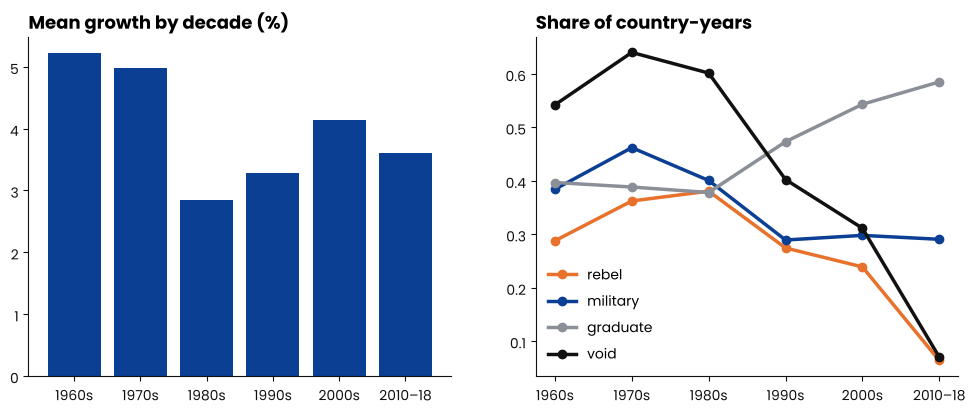

In [7]:
E = main_raw.copy()
E["decade"] = np.where(E.year >= 2010, "2010–18", (E.year // 10 * 10).astype(int).astype(str) + "s")
DEC = ["1960s", "1970s", "1980s", "1990s", "2000s", "2010–18"]
by_dec = (E.groupby("decade").agg(growth=("growth", "mean"), sd=("growth", "std"), rebel=("rebel", "mean"), military=("milservice", "mean"),
          graduate=("grad_edu", "mean"), irregular=("irregular_entry", "mean"), void=("void", "mean"), N=("growth", "size")).reindex(DEC))
by_reg = (E.groupby("region").agg(growth=("growth", "mean"), sd=("growth", "std"), rebel=("rebel", "mean"), void=("void", "mean"),
          N=("growth", "size"), countries=("country_id", "nunique")).sort_values("growth"))
display(by_dec.style.format({c: "{:.3f}" for c in by_dec.columns if c != "N"} | {"N": "{:,.0f}"}).set_caption("EDA 1 — By decade: mean growth and shares of country-years"))
display(by_reg.style.format({c: "{:.3f}" for c in by_reg.columns if c not in ("N", "countries")}).set_caption("EDA 2 — By region"))

# noise and persistence
ac = float(E[["growth", "lag_growth"]].corr().iloc[0, 1])
spl = E.groupby("spell_id").size(); cnt = E.groupby("country_id").spell_id.nunique()
print(f"Growth: mean {E.growth.mean():.2f}%, SD {E.growth.std():.2f}; correlation with last year's growth {ac:.2f}")
print(f"Leadership spells: mean {spl.mean():.1f} years in sample, median {spl.median():.0f}; {cnt.mean():.1f} spells per country "
      f"({(cnt >= 3).mean() * 100:.0f}% of countries have 3 or more)")

# raw differences vs within-country differences
eq1 = fe_ols(main, "growth", TRAITS + LEADER_CTRL + DYN + INST, FE2)   # = Table 3, column (4)
raw = {}
for k in TRAITS + ["void"]:
    a, b0 = E.loc[E[k] == 1, "growth"].mean(), E.loc[E[k] == 0, "growth"].mean()
    rfe = fe_ols(main, "growth", [k], FE2)
    raw[k] = {"with": a, "without": b0, "raw_diff": a - b0, "fe_b": float(rfe.params[k]), "fe_se": float(rfe.bse[k]), "fe_p": float(rfe.pvalues[k]),
              "eq1_b": float(eq1.params[k]) if k in eq1.params else np.nan,
              "eq1_p": float(eq1.pvalues[k]) if k in eq1.params else np.nan}
tr = pd.DataFrame(raw).T.rename(index={**LABELS, "void": "Institutional void"})
display(tr.style.format("{:.3f}").set_caption("EDA 3 — Growth with vs without each trait: raw gap, within-country gap (country + year FE), and Eq. 1"))
C = E[TRAITS].corr(); off = C.where(~np.eye(len(TRAITS), dtype=bool)).abs()
i, j = np.unravel_index(np.nanargmax(off.values), off.shape)
print(f"Largest correlation between two traits: {TRAITS[i]} and {TRAITS[j]}, {C.iloc[i, j]:.2f} (no severe collinearity)")
RESULTS["eda"] = {"by_decade": by_dec.reset_index().to_dict("records"), "by_region": by_reg.reset_index().to_dict("records"),
                  "autocorr": ac, "spell_mean": float(spl.mean()), "spell_median": float(spl.median()), "spells_per_country": float(cnt.mean()),
                  "share_3plus": float((cnt >= 3).mean()), "raw": raw, "max_corr": {"a": TRAITS[i], "b": TRAITS[j], "r": float(C.iloc[i, j])},
                  "growth_mean": float(E.growth.mean()), "growth_sd": float(E.growth.std())}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].bar(DEC, by_dec.growth, color=BLUE); axes[0].set_title("Mean growth by decade (%)", loc="left")
for col, c in [("rebel", ORANGE), ("military", BLUE), ("graduate", GREY), ("void", INK)]:
    axes[1].plot(DEC, by_dec[col], marker="o", color=c, lw=2.5, label=col)
axes[1].set_title("Share of country-years", loc="left"); axes[1].legend(frameon=False)
fig.savefig(f"{OUT}/fig_eda_decades.png"); plt.show()

In [8]:
# EDA 4 — who were the leaders? Unique leaders in the main sample by education, military background and path to power
CY = main_raw.copy()
CY["edu_cat"] = CY.leveledu.map({0: "Primary", 1: "Secondary", 2: "University", 3: "Graduate degree"})
CY["mil_cat"] = np.select([CY.milservice == 0, (CY.milservice == 1) & (CY.combatvet == 0), CY.combatvet == 1],
                          ["No military service", "Military service, no combat", "Combat veteran"], default=None)
CY["career"] = (pd.to_numeric(CY.militarycareer, errors="coerce") == 1).astype(float)
CY["seized"] = ((CY.rebel == 1) & (CY.irregular_entry == 1)).astype(float)
nL = CY.leaderid.nunique(); nY = len(CY)
rows = []
def add(panel, label, mask):
    sub = CY[mask]
    rows.append({"Panel": panel, "Category": label, "Leaders": sub.leaderid.nunique(), "% of leaders": 100 * sub.leaderid.nunique() / nL,
                 "Country-years": len(sub), "% of country-years": 100 * len(sub) / nY, "Mean growth (%)": sub.growth.mean()})
for c in ["Primary", "Secondary", "University", "Graduate degree"]:
    add("A. Highest education", c, CY.edu_cat == c)
for c in ["No military service", "Military service, no combat", "Combat veteran"]:
    add("B. Military background", c, CY.mil_cat == c)
add("B. Military background", "Career officers (among all who served)", CY.career == 1)
add("C. Path to power", "Former rebel", CY.rebel == 1)
add("C. Path to power", "Irregular entry (coup, revolt)", CY.irregular_entry == 1)
add("C. Path to power", "Former rebel who seized power", CY.seized == 1)
T2L = pd.DataFrame(rows).set_index(["Panel", "Category"])
display(T2L.style.format({"Leaders": "{:,.0f}", "% of leaders": "{:.1f}", "Country-years": "{:,.0f}", "% of country-years": "{:.1f}",
                          "Mean growth (%)": "{:.2f}"}).set_caption(f"EDA 4 — Who governed: {nL} leaders, {nY:,} country-years (main sample)"))
print("Leaders can appear in more than one row of a panel only if their background changes between spells (rare).")

# where former rebels governed (for the motivation map): panel 1962–2018, all country-years with a coded rebel past
RP = panel[panel.year.between(1962, 2018) & (panel.rebel == 1)]
top = (RP.groupby(["country_id", "leadername"]).year.agg(["size", "min", "max"]).reset_index().sort_values("size", ascending=False)
         .drop_duplicates("country_id"))
cnt = RP.groupby("country_id").size().rename("rebel_years")
rebel_map = top.merge(cnt, on="country_id").rename(columns={"size": "leader_years", "min": "from", "max": "to"})
rebel_map = rebel_map.merge(panel.drop_duplicates("country_id")[["country_id", "country"]], on="country_id", how="left")
print(f"Countries ever governed by a former rebel, 1962–2018: {len(rebel_map)}; country-years: {len(RP):,} "
      f"({100 * len(RP) / panel[panel.year.between(1962, 2018) & panel.rebel.notna()].shape[0]:.1f}% of coded country-years)")
display(rebel_map.sort_values("rebel_years", ascending=False).head(15))
RESULTS["eda_leaders"] = {"table": T2L.reset_index().to_dict("records"), "n_leaders": int(nL), "n_cy": int(nY)}
RESULTS["rebel_map"] = {"countries": rebel_map.to_dict("records"), "share": float(len(RP) / panel[panel.year.between(1962, 2018) & panel.rebel.notna()].shape[0]),
                        "n_countries": int(len(rebel_map))}

Leaders can appear in more than one row of a panel only if their background changes between spells (rare).
Countries ever governed by a former rebel, 1962–2018: 109; country-years: 2,203 (27.3% of coded country-years)


,country_id,leadername,leader_years,from,to,rebel_years,country
0,CUB,Castro,43,1962,2004,56,Cuba
33,LAO,Phomivan,17,1976,1992,51,Laos
17,IRQ,Saddam Hussein,24,1980,2003,51,Iraq
12,YEM,Saleh al-Hashidi,26,1979,2004,46,North Yemen
29,MZM,Chissano,18,1987,2004,44,Mozambique
20,GUI,Toure,22,1962,1983,43,Guinea
42,ALG,Boumedienne,14,1965,1978,43,Algeria
31,DRV,Le Duan,18,1969,1986,42,Vietnam
4,DRC,Mobutu,31,1966,1996,42,Democratic Republic of the Congo
1,TOG,Eyadema,38,1967,2004,38,Togo


**Reading the EDA.** (i) Growth was fastest in the 1960s and 1970s (5.2% and 5.0%) and slowest in the 1980s (2.9%), the debt-crisis decade: the reason every regression has year fixed effects. Asia-Pacific and the Middle East and North Africa grew fastest; the Middle East is also the most volatile (SD 7.1). (ii) Former rebels governed 27–38% of country-years from the 1960s to the 1990s, then fell to 6% in 2010–18. The institutional void shrank from 64% of country-years in the 1970s to 7% in 2010–18, while graduate leaders rose from 40% to 59%. (iii) Growth is noisy (SD 5.3 around a mean of 3.89%) and persistent (correlation with last year's growth 0.37). Persistence is why the leader fixed-effects test needs a placebo benchmark and why Eq. 1 controls for lagged growth. Leaders change often enough to identify within-country effects: 6.3 spells per country, and 75% of countries have three or more.

(iv) **The raw data point the wrong way.** Country-years under former rebels grow 0.26 pp *faster* than others, and the void grows 0.70 pp faster. Within countries both gaps vanish (−0.06 and −0.30), and with Eq. 1's controls the rebel gap turns to −0.85. Raw comparisons confuse who governs with where and when: former rebels and weak constraints are concentrated in poorer, catching-up economies. Section 5.1 shows the mechanism. The largest correlation between two traits is rebel and irregular entry (0.56), not high enough to cause collinearity problems.

(v) **Who governed (EDA 4).** Most leaders were university-educated civilians: 47% held a graduate degree and 40% a first degree; 71% never served in the military and 18% were combat veterans. Career officers (20% of leaders) are a subset of those who served, so Panel B does not sum to 100. 199 leaders (23%) had a rebel past, yet they governed 29% of country-years: former rebels stay in office longer. 103 of them seized power by coup or revolt. Raw growth falls with education (5.68% under the 18 leaders with only primary schooling, 3.66% under graduates) and is higher under combat veterans (4.46%) than under leaders who never served (3.65%). Like the gaps in (iv), these raw differences mix who governs with where and when, which is why the regressions compare leaders within the same country.

## 4. Table 2 — Do leaders matter? Leader fixed effects and a placebo benchmark

**What is a leader fixed effect?** A dummy variable that equals 1 in every year a particular leader is in office (one dummy per leadership spell). Its coefficient is that leader's average growth, after removing the country's own average and that year's world-wide shock. If leaders were interchangeable, these dummies would add nothing.

**The standard test (Besley et al. 2011, Table 2).** Add all leader dummies to a model with country and year fixed effects and test whether they are jointly zero with an F-test. Besley et al. find F = 2.37.

**The problem (Jones & Olken 2005, p. 841).** Growth is persistent: good and bad years cluster. Any dummy that groups consecutive years "explains" some of that clustering, even if it has nothing to do with leaders. So a large F could just mean growth is serially correlated.

**Our placebo benchmark.** Within each country we keep the exact lengths of the real tenures but shuffle their order, creating fake leaders with the same tenure structure and the same number of dummies. We repeat this 500 times. If real leaders matter, the real F should sit far to the right of the placebo distribution. The share of placebo F-statistics at least as large as the real one is a permutation p-value that is robust to serial correlation.

1000 placebo regressions in 142s
Exact dummy-variable F = 1.9904 (alternating projections: 1.9904)


,(A) GDP growth,(B) Growth net of lagged growth and income
Country + year FE: R²,0.175,0.002
+ leader-spell FE: R²,0.393,0.163
Country + year FE: adjusted R²,0.149,-0.029
+ leader-spell FE: adjusted R²,0.261,-0.019
F-test: leader effects jointly zero,1.99,1.06
Degrees of freedom,"(1148, 6,359)","(1106, 6,092)"
Classical p-value,1.0e-60,9.8e-02
Placebo leaders: mean F (500 draws),2.09,1.15
Placebo leaders: 95th percentile of F,2.24,1.25
Permutation p-value: share of placebo F ≥ real F,0.880,0.946


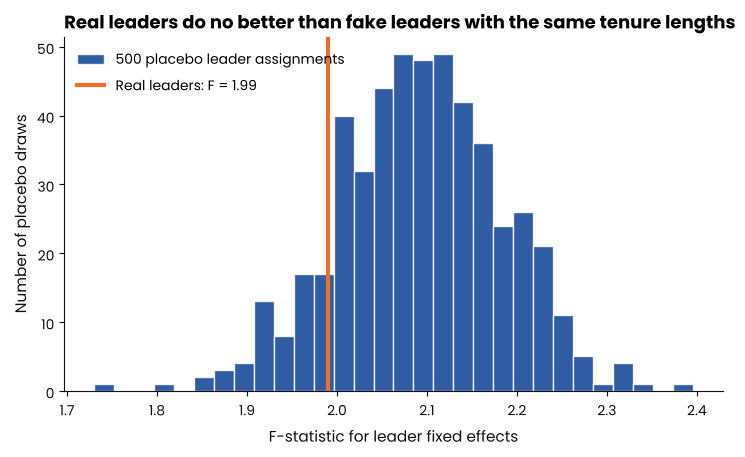

In [9]:
def ap_resid(y, g1, g2, tol=1e-11, maxit=5000):
    # Residual of y after removing two sets of fixed effects (alternating projections).
    r = np.asarray(y, float).copy(); c1 = pd.factorize(g1)[0]; c2 = pd.factorize(g2)[0]
    n1, n2 = np.bincount(c1), np.bincount(c2)
    for _ in range(maxit):
        r = r - (np.bincount(c1, weights=r) / n1)[c1]
        r_new = r - (np.bincount(c2, weights=r) / n2)[c2]
        if np.max(np.abs(r_new - r)) < tol:
            return r_new
        r = r_new
    return r

def leader_F(y, country, year, leader):
    e_r, e_u = ap_resid(y, country, year), ap_resid(y, leader, year)
    rss_r, rss_u = float(e_r @ e_r), float(e_u @ e_u)
    n, nl, nc, nt = len(y), len(np.unique(leader)), len(np.unique(country)), len(np.unique(year))
    q, df2 = nl - nc, n - (nl + nt - 1); tss = float(((y - y.mean()) ** 2).sum())
    F = ((rss_r - rss_u) / q) / (rss_u / df2)
    return dict(F=F, q=q, df2=df2, p=float(stats.f.sf(F, q, df2)), r2_r=1 - rss_r / tss, r2_u=1 - rss_u / tss,
                r2adj_r=1 - (rss_r / (n - nc - nt + 1)) / (tss / (n - 1)), r2adj_u=1 - (rss_u / df2) / (tss / (n - 1)),
                n=n, spells=nl, countries=nc)

def fake_spells(df, rng):
    fake = np.empty(len(df), dtype=object)
    for c, idx in df.groupby("country_id").indices.items():
        runs = (df.spell_id.iloc[idx] != df.spell_id.iloc[idx].shift()).cumsum()
        lengths = rng.permutation(runs.value_counts(sort=False).reindex(runs.unique()).to_numpy())
        fake[idx] = [f"{c}_{j}" for j in np.repeat(np.arange(len(lengths)), lengths)]
    return fake

def spell_sample(df):
    df = df.sort_values(["country_id", "year"]).reset_index(drop=True)
    df = df[df.groupby("spell_id").year.transform("count") >= 2]
    return df[df.groupby("country_id").spell_id.transform("nunique") >= 2].reset_index(drop=True)

LF = spell_sample(panel[panel.year.between(1961, 2025)].dropna(subset=["growth"]))
dyn = panel[panel.year.between(1961, 2025)].dropna(subset=["growth"] + DYN)
r_dyn = fe_ols(dyn, "growth", DYN, FE2, cluster=None)
LD = spell_sample(dyn.loc[r_dyn.resid.index].assign(e=r_dyn.resid.values))

rng = np.random.default_rng(SEED); B = 500; t0 = time.time(); out = {}
for key, data, y in [("A", LF, "growth"), ("B", LD, "e")]:
    yv = data[y].to_numpy(float)
    real = leader_F(yv, data.country_id.to_numpy(), data.year.to_numpy(), data.spell_id.astype(str).to_numpy())
    Fs = np.array([leader_F(yv, data.country_id.to_numpy(), data.year.to_numpy(), fake_spells(data, rng))["F"]
                   for _ in range(B)])
    real.update(placebo_mean=float(Fs.mean()), placebo_p95=float(np.percentile(Fs, 95)),
                perm_p=float((Fs >= real["F"]).mean()), placebo=Fs.tolist())
    out[key] = real
print(f"{2 * B} placebo regressions in {time.time() - t0:.0f}s")

# exact check of the real F with explicit dummies (no alternating projections)
rr = fe_ols(LF, "growth", [], FE2, cluster=None); ru = fe_ols(LF, "growth", [], ("spell_id", "year"), cluster=None)
F_exact = ((rr.rss - ru.rss) / (ru.K - rr.K)) / (ru.rss / (ru.nobs - ru.K))
print(f"Exact dummy-variable F = {F_exact:.4f} (alternating projections: {out['A']['F']:.4f})")

rows = [("Country + year FE: R²", "r2_r", "{:.3f}"), ("+ leader-spell FE: R²", "r2_u", "{:.3f}"),
        ("Country + year FE: adjusted R²", "r2adj_r", "{:.3f}"), ("+ leader-spell FE: adjusted R²", "r2adj_u", "{:.3f}"),
        ("F-test: leader effects jointly zero", "F", "{:.2f}"), ("Degrees of freedom", None, None),
        ("Classical p-value", "p", "{:.1e}"), ("Placebo leaders: mean F (500 draws)", "placebo_mean", "{:.2f}"),
        ("Placebo leaders: 95th percentile of F", "placebo_p95", "{:.2f}"),
        ("Permutation p-value: share of placebo F ≥ real F", "perm_p", "{:.3f}"),
        ("Observations", "n", "{:,}"), ("Leadership spells", "spells", "{:,}"), ("Countries", "countries", "{:,}")]
t2 = pd.DataFrame(index=[r[0] for r in rows], columns=["(A) GDP growth", "(B) Growth net of lagged growth and income"])
for lab, key, f in rows:
    for col, k in zip(t2.columns, ["A", "B"]):
        t2.loc[lab, col] = f"({out[k]['q']}, {out[k]['df2']:,})" if key is None else f.format(out[k][key])
display(t2.style.set_caption("Table 2 — Leader fixed effects: classical F-test and placebo benchmark (1961–2025)"))
RESULTS["table2"] = {k: {kk: vv for kk, vv in v.items() if kk != "placebo"} for k, v in out.items()}
RESULTS["table2"]["F_exact"] = float(F_exact)
pd.DataFrame({"placebo_F_A": out["A"]["placebo"], "placebo_F_B": out["B"]["placebo"]}).to_csv(f"{OUT}/placebo_F.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.hist(out["A"]["placebo"], bins=30, color=BLUE, alpha=0.85, edgecolor="white", label="500 placebo leader assignments")
ax.axvline(out["A"]["F"], color=ORANGE, lw=3, label=f"Real leaders: F = {out['A']['F']:.2f}")
ax.set_xlabel("F-statistic for leader fixed effects"); ax.set_ylabel("Number of placebo draws")
ax.set_title("Real leaders do no better than fake leaders with the same tenure lengths", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.savefig(f"{OUT}/fig_placebo_leaders.png"); plt.show()

**Reading Table 2** (this test uses 1961–2025, as it needs no xconst)**.** Adding a dummy for every leadership spell raises the R² from 0.175 to 0.393, and the classical F-test rejects "no leader effects" overwhelmingly (F = 1.99, p ≈ 10⁻⁶⁰), the same kind of evidence Besley et al. (2011) report. The placebo benchmark changes the reading. Fake leaders, built from the same tenure lengths in a shuffled order, produce F-statistics that are just as large: the real F sits inside the placebo distribution, not in its right tail. Net of lagged growth and income (column B), even the classical test no longer rejects at 5%.

**What this means.** The joint F-test cannot separate leaders from the persistence of growth, so in our panel "do leaders matter?" cannot be settled with leader fixed effects alone (Easterly & Pennings 2025 likewise stress how noisy estimated leader effects are). We therefore ask a sharper question the data can answer: do *specific, observable* backgrounds predict growth within the same country?

## 5. Table 3 — The main equation (Eq. 1)

Section 4 shows we cannot tell real leaders from fake ones by asking whether they *jointly* matter. So we ask a sharper, testable question: **do specific, observable backgrounds predict growth?**

$$\mathrm{Growth}_{c,t} = \beta_0 + \beta_1\mathrm{Grad}_{c,t} + \beta_2\mathrm{MilNoCombat}_{c,t} + \beta_3\mathrm{Combat}_{c,t} + \beta_4\mathrm{Rebel}_{c,t} + \beta_5\mathrm{Irregular}_{c,t}$$
$$+\; \beta_6\mathrm{Age}_{c,t} + \beta_7\mathrm{Exper}_{c,t} + \rho\ln\mathrm{GDPpc}_{c,t-1} + \phi\,\mathrm{Growth}_{c,t-1} + \lambda\,\mathrm{xconst}_{c,t} + \alpha_c + \gamma_t + \varepsilon_{c,t}$$

Continuous controls (age, experience, lagged income, lagged growth, xconst) enter as deviations from their sample means (Table 1). This leaves every slope unchanged and gives β₀ an economic meaning instead of "growth at an income of one dollar" (ln GDP pc = 0).

**Why each term is included**

| Term | Role | Why it is in the equation |
|---|---|---|
| β₀ | Intercept | Predicted growth under the reference leader — civilian, no graduate degree, no rebel past, regular entry — at average age, experience, income, lagged growth and constraints. Every β is measured against this benchmark |
| β₁ Grad | Parameter of interest | Human-capital channel: Besley et al. (2011) find growth falls after a graduate leader leaves |
| β₂ MilNoCombat, β₃ Combat | Parameters of interest | Horowitz & Stam (2014): military socialisation and combat experience shape behaviour in different ways, so they are separated |
| β₄ Rebel | Parameter of interest | Insurgent or coup experience: selected for risk-taking and coercion rather than administration |
| β₅ Irregular | Parameter of interest | How the leader came to power: illegitimate entry shortens horizons and invites counter-coups |
| β₆ Age, β₇ Experience | Leader controls | Correlated with the traits (officers enter older, rebels younger) and with policy; omitting them would load their effect onto β₂–β₄ |
| ρ ln GDPpc(t−1) | Convergence | Poorer countries grow faster (Solow). Lagged one year because growth at *t* is built from GDP at *t* |
| φ Growth(t−1) | Persistence | Growth carries over, and new leaders often arrive after a bad year; without it a leader gets credit for normal recovery |
| λ xconst | Formal institutions | Military and rebel rulers coincide with weak checks; without it β would partly measure institutions |
| α_c | Country fixed effects | Remove everything fixed about a country: geography, colonial origin, legal origin, culture, ethnic make-up |
| γ_t | Year fixed effects | Remove world-wide shocks: oil crises (1973, 1979), the debt crisis (1982), 2008 |
| ε | Error | Clustered by country |

**What is deliberately left out, and why**

- **Investment, inflation, trade openness, public spending** — these are *channels* through which leaders act. Controlling for them would absorb the effect we want to measure ("bad controls", Angrist & Pischke 2009).
- **Leader fixed effects** — traits are constant within a spell, so they are perfectly collinear with leader dummies. One cannot estimate both.
- **Current-year income** — mechanically related to current growth.
- **Polity2 and participation in the baseline** — `xconst` is a component of Polity2; they enter in column (5) as additional institutional controls.
- **Country-specific trends, region × year effects** — demanding specifications that use up much of the variation; reported as robustness (column 6 and Table 8).

**Build-up.** Column (1) has only the traits and fixed effects; each later column adds one block. Watching how β moves as controls enter tells us which omitted factors matter (in the spirit of Altonji, Elder & Taber 2005). Column (4) is the preferred specification, Eq. 1.

,(1),(2),(3),(4),(5),(6)
Constant (β₀),3.958***,4.022***,4.102***,4.150***,4.149***,3.828***
,(0.216),(0.203),(0.155),(0.165),(0.164),(0.190)
Graduate degree,−0.160,−0.154,−0.168,−0.143,−0.138,−0.092
,(0.229),(0.224),(0.161),(0.159),(0.156),(0.175)
"Military service, no combat",0.222,0.237,0.506,0.456,0.446,0.352
,(0.417),(0.398),(0.312),(0.315),(0.320),(0.356)
Combat veteran,0.871*,0.768*,0.577*,0.551,0.542,0.544*
,(0.463),(0.459),(0.342),(0.345),(0.345),(0.315)
Former rebel,−0.174,−0.298,−0.804**,−0.846**,−0.841**,−0.751**
,(0.435),(0.425),(0.325),(0.329),(0.330),(0.323)


Former rebel, Eq. 1: beta4 = -0.846 (SE 0.329), p = 0.011
Average rebel spell in the sample: 7.9 years -> GDP about 6.5% lower by the end of the spell
Long-run effect beta4/(1-phi), phi = 0.272: -1.163 pp per year (delta-method SE 0.456)


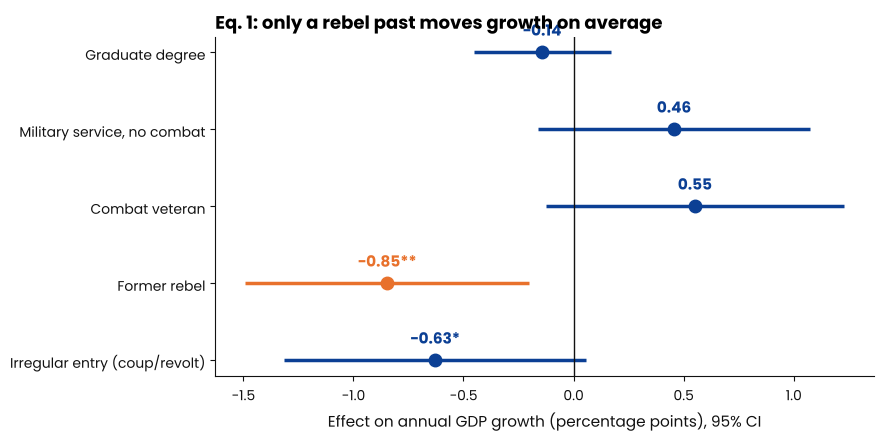

In [10]:
def ry(df):
    return df.assign(region_year=df.region.astype(str) + "_" + df.year.astype(str))

spec = {
    "(1)": (TRAITS, FE2, main),
    "(2)": (TRAITS + LEADER_CTRL, FE2, main),
    "(3)": (TRAITS + LEADER_CTRL + DYN, FE2, main),
    "(4)": (TRAITS + LEADER_CTRL + DYN + INST, FE2, main),
    "(5)": (TRAITS + LEADER_CTRL + DYN + INST + ["polity", "parcomp"], FE2, main),
    "(6)": (TRAITS + LEADER_CTRL + DYN + INST, ("country_id", "region_year"), ry(main.dropna(subset=["region"]))),
}
T3 = {k: fe_ols(df, "growth", X, fe) for k, (X, fe, df) in spec.items()}
w2 = {k: within_r2(r) for k, r in T3.items()}
extra = [("Country FE", ["✓"] * 6), ("Year FE", ["✓"] * 5 + [""]), ("Region × year FE", [""] * 5 + ["✓"]),
         ("Observations", [f"{r.nobs:,}" for r in T3.values()]), ("Countries", [str(r.G) for r in T3.values()]),
         ("R²", [f"{r.r2:.3f}" for r in T3.values()]), ("Within R²", [f"{w2[k]:.3f}" for k in T3])]
rows = ["const"] + TRAITS + LEADER_CTRL + DYN + INST + ["polity", "parcomp"]
html, rec3 = reg_table(T3, rows, LABELS, extra,
    title="Table 3 — Leader backgrounds and GDP growth: the main equation (Eq. 1), 1961–2018",
    note="Dependent variable: real GDP growth (%), winsorised. Column (4) is the preferred specification. Standard errors "
         "clustered by country in parentheses; * p<0.10, ** p<0.05, *** p<0.01 (t with G−1 df). Baseline category: a civilian, "
         "non-graduate leader without a rebel past who entered office regularly.")
display(HTML(html))
for k, r in T3.items():
    rec3[k].update(N=r.nobs, G=r.G, r2=r.r2, r2_within=w2[k])
RESULTS["table3"] = rec3

b, se, p = T3["(4)"].params["rebel"], T3["(4)"].bse["rebel"], T3["(4)"].pvalues["rebel"]
spell_len = main[main.rebel == 1].groupby("spell_id").size().mean()
level = 100 * (1 - (1 + b / 100) ** spell_len)
phi = T3["(4)"].params["lag_growth"]
lr = b / (1 - phi)                                             # long-run effect of a sustained change
grad = np.array([1 / (1 - phi), b / (1 - phi) ** 2])           # delta method
Vsub = T3["(4)"].cov.loc[["rebel", "lag_growth"], ["rebel", "lag_growth"]].to_numpy()
lr_se = float(np.sqrt(grad @ Vsub @ grad))
print(f"Former rebel, Eq. 1: beta4 = {b:.3f} (SE {se:.3f}), p = {p:.3f}")
print(f"Average rebel spell in the sample: {spell_len:.1f} years -> GDP about {level:.1f}% lower by the end of the spell")
print(f"Long-run effect beta4/(1-phi), phi = {phi:.3f}: {lr:.3f} pp per year (delta-method SE {lr_se:.3f})")
RESULTS["rebel_level"] = {"spell_years": float(spell_len), "gdp_loss_pct": float(level), "phi": float(phi),
                          "long_run": float(lr), "long_run_se": lr_se}

r4 = T3["(4)"]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
names = TRAITS[::-1]
for i, v in enumerate(names):
    c = ORANGE if v == "rebel" else BLUE
    ax.errorbar(r4.params[v], i, xerr=1.96 * r4.bse[v], fmt="o", color=c, ms=9, capsize=0, lw=2.5)
    ax.text(r4.params[v], i + 0.22, f"{num(r4.params[v], 2)}{stars(r4.pvalues[v])}", ha="center", color=c, fontsize=11, fontweight="bold")
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(len(names))); ax.set_yticklabels([LABELS[v] for v in names])
ax.set_xlabel("Effect on annual GDP growth (percentage points), 95% CI")
ax.set_title("Eq. 1: only a rebel past moves growth on average", loc="left")
fig.savefig(f"{OUT}/fig_main_coefplot.png"); plt.show()

In [11]:
# Table 3B — the usual suspects: graduate degree and military service alone (the leader traits studied in the literature)
gmA = fe_ols(main, "growth", ["grad_edu", "milservice"], FE2)
gmB = fe_ols(main, "growth", ["grad_edu", "milservice"] + LEADER_CTRL + DYN + INST, FE2)
T3B = {"(A) Grad + military, FE only": gmA, "(B) + Eq. 1 controls": gmB, "(C) Eq. 1, all five backgrounds": T3["(4)"]}
html, rec3b = reg_table(T3B, ["const", "grad_edu", "milservice"] + TRAITS[1:] + LEADER_CTRL + DYN + INST, LABELS,
    [("Country and year FE", ["✓"] * 3), ("Observations", [f"{r.nobs:,}" for r in T3B.values()]),
     ("R² (within R²)", [f"{r.r2:.3f} ({within_r2(r):.3f})" for r in T3B.values()])],
    title="Table 3B — Education and military service on their own, then with the full set of backgrounds",
    note="Same sample as Table 3. Military service = any prior service (combat or not). Column (C) repeats Table 3, column (4).")
display(HTML(html))
for k, r in T3B.items():
    rec3b[k].update(N=r.nobs, r2=r.r2, r2_within=within_r2(r))
RESULTS["table3b"] = rec3b

,"(A) Grad + military, FE only",(B) + Eq. 1 controls,"(C) Eq. 1, all five backgrounds"
Constant (β₀),3.856***,3.834***,4.150***
,(0.165),(0.121),(0.165)
Graduate degree,−0.123,−0.038,−0.143
,(0.210),(0.152),(0.159)
Military service (any),0.242,0.198,
,(0.344),(0.257),
"Military service, no combat",,,0.456
,,,(0.315)
Combat veteran,,,0.551
,,,(0.345)


**Reading Table 3.** Column (1): with only country and year fixed effects, no background is significant at 5% (combat +0.87 and irregular entry −0.74 at 10%). Column (2) adds age and experience. Column (3) is the turning point: once lagged income and lagged growth enter, the former-rebel coefficient moves from −0.30 to −0.80 and becomes significant, and the within-R² rises from 0.7% to 10.4% (Section 5.1 explains why). Columns (4)–(6) add executive constraints, then Polity2 and participation, then replace year effects with region × year effects; the rebel coefficient barely moves (−0.85, −0.84, −0.75).

**The preferred estimate (column 4).** β₀ = 4.15: a civilian leader without a graduate degree or a rebel past who took office regularly presides over 4.2% growth at average characteristics. β₄ = −0.846 (SE 0.329, p = 0.011): under a former rebel, growth is 0.85 percentage points lower per year than under that reference leader in the same country. Over the average rebel spell in the sample (7.9 years) this compounds to GDP about 6.5% lower; because growth is persistent (φ = 0.27), the long-run effect of a sustained change is −1.16 pp per year (SE 0.46). Irregular entry is negative but only significant at 10% (−0.63); education, military service and combat experience have no significant *average* effect.

The controls behave as theory predicts: strong conditional convergence (ρ = −3.06: a country 10% richer than its own average grows 0.31 pp more slowly) and persistence (φ = 0.27). Executive constraints have no independent effect once country fixed effects are included (λ = −0.10, n.s.).

**Reading Table 3B (education and military service alone).** The two traits the literature has focused on show no association with growth within countries. On their own (column A), a graduate degree is −0.12 (p = 0.56) and any military service +0.24 (p = 0.48), and together they explain 0.1% of the within-country variation in growth. Adding Eq. 1's controls (column B) changes neither (−0.04 and +0.20). Splitting military service into combat and non-combat and adding the rebel and entry dummies (column C, = Table 3 column 4) leaves education and military service insignificant; the rebel past is the background that moves growth.

### Table 3C — Why don't education and military service show up? Comparing with Jones–Olken and Besley et al.

Jones and Olken (2005) do **not** estimate education or military effects: they use 57 deaths of leaders in office to show that *leaders as a group* matter, and that the effect is concentrated in autocracies (Polity ≤ 0). Besley, Montalvo and Reynal-Querol (2011) do test education: using 215 exits through natural death or illness, 1875–2004, they find growth falls 0.7 pp a year after a leader with a graduate degree dies, and 2.1 pp if the successor has no graduate degree. Our design differs (all transitions, 1962–2018, within-country panel), so we check whether the null survives when we move our sample and definitions towards theirs.

In [12]:
# Table 3C — education and military service under the literature's definitions and samples
POL0 = MEANS["polity"]                                  # polity is centred in `main`; add the mean back to get the Polity2 score
autoc, democ = main[main.polity + POL0 <= 0], main[main.polity + POL0 > 0]
mc = main.assign(college=main.higher_edu.astype(float))
specs3c = [("(1) Baseline: grad + military, FE only", main, ["grad_edu", "milservice"], "grad_edu"),
           ("(2) College degree instead of graduate (Besley et al. robustness)", mc, ["college", "milservice"], "college"),
           ("(3) Besley et al. years only, 1962–2004", main[main.year <= 2004], ["grad_edu", "milservice"], "grad_edu"),
           ("(4) Autocracies only, Polity2 ≤ 0 (Jones–Olken split)", autoc, ["grad_edu", "milservice"], "grad_edu"),
           ("(5) Democracies only, Polity2 > 0", democ, ["grad_edu", "milservice"], "grad_edu"),
           ("(6) Autocracies only, full Eq. 1", autoc, TRAITS + LEADER_CTRL + DYN + INST, "grad_edu")]
rows3c, rec3c = [], {}
for lab, d, X, ed in specs3c:
    r = fe_ols(d, "growth", X, FE2)
    mil = "milservice" if "milservice" in X else "combatvet"
    row = {"Specification": lab, "Education": f"{num(r.params[ed])}{stars(r.pvalues[ed])} ({r.bse[ed]:.2f})",
           "Military" + (" (combat in (6))" if False else ""): f"{num(r.params[mil])}{stars(r.pvalues[mil])} ({r.bse[mil]:.2f})",
           "Former rebel": f"{num(r.params['rebel'])}{stars(r.pvalues['rebel'])} ({r.bse['rebel']:.2f})" if "rebel" in X else "", "N": f"{r.nobs:,}"}
    rows3c.append(row)
    rec3c[lab] = {"edu": {"b": r.params[ed], "se": r.bse[ed], "p": r.pvalues[ed]}, "mil": {"b": r.params[mil], "se": r.bse[mil], "p": r.pvalues[mil]},
                  "mil_var": mil, "N": r.nobs, **({"rebel": {"b": r.params["rebel"], "se": r.bse["rebel"], "p": r.pvalues["rebel"]}} if "rebel" in X else {})}
display(pd.DataFrame(rows3c).set_index("Specification").style.set_caption(
    "Table 3C — Education and military service under alternative definitions and samples (country and year FE; SEs clustered by country). "
    "Column (6) reports combat veterans in the military column."))
RESULTS["table3c"] = rec3c

# Multicollinearity: variance inflation factors for the Eq. 1 regressors, raw and after removing country and year effects
def vif_table(df):
    out = {}
    for c in df.columns:
        o = df.drop(columns=c); A = np.column_stack([np.ones(len(o)), o.values])
        b = np.linalg.lstsq(A, df[c].values, rcond=None)[0]; e = df[c].values - A @ b
        out[c] = 1 / (e.var() / df[c].values.var())
    return pd.Series(out)
Xv = main[TRAITS + LEADER_CTRL + DYN + INST].astype(float)
Xw = Xv.apply(lambda col: pd.Series(ap_resid(col.values, main.country_id.values, main.year.values), index=Xv.index))
VIF = pd.DataFrame({"VIF (raw)": vif_table(Xv), "VIF (within country and year)": vif_table(Xw)}).rename(index=LABELS).round(2)
display(VIF.style.set_caption("Variance inflation factors for the Eq. 1 regressors (rule of thumb: worry above 5–10)"))
cr, cw = np.corrcoef(Xv.lag_lngdppc, Xv.lag_growth)[0, 1], np.corrcoef(Xw.lag_lngdppc, Xw.lag_growth)[0, 1]
print(f"Correlation of ln GDP pc (t−1) and growth (t−1): raw {cr:.3f}, within country and year {cw:.3f}")
RESULTS["vif"] = {"raw": VIF["VIF (raw)"].to_dict(), "within": VIF["VIF (within country and year)"].to_dict(), "corr_raw": cr, "corr_within": cw}

,Education,Military,Former rebel,N
Specification,,,,
"(1) Baseline: grad + military, FE only",−0.123 (0.21),0.242 (0.34),,"5,465"
(2) College degree instead of graduate (Besley et al. robustness),0.174 (0.53),0.277 (0.34),,"5,465"
"(3) Besley et al. years only, 1962–2004",−0.137 (0.26),0.390 (0.39),,"4,862"
"(4) Autocracies only, Polity2 ≤ 0 (Jones–Olken split)",−0.139 (0.62),0.853 (0.75),,"2,520"
"(5) Democracies only, Polity2 > 0",−0.209 (0.20),0.130 (0.31),,"2,945"
"(6) Autocracies only, full Eq. 1",0.058 (0.48),2.078** (0.95),−2.086** (0.83),"2,520"


,VIF (raw),VIF (within country and year)
Graduate degree,1.240000,1.150000
"Military service, no combat",1.280000,1.220000
Combat veteran,1.580000,1.510000
Former rebel,1.820000,1.570000
Irregular entry (coup/revolt),1.960000,1.640000
Age,1.210000,1.130000
Political experience (years),1.400000,1.240000
ln GDP per capita (t−1),1.390000,1.090000
GDP growth (t−1),1.020000,1.010000
Executive constraints (xconst),1.920000,1.380000


Correlation of ln GDP pc (t−1) and growth (t−1): raw -0.028, within country and year 0.044


**Reading Table 3C.** The education null is not an artefact of our definitions or years. A college dummy instead of a graduate degree (+0.17, p = 0.74), Besley et al.'s years only (−0.14, p = 0.60), and the Jones–Olken autocracy/democracy split (−0.14 and −0.21, both n.s.) all leave education insignificant; military service is never significant on its own either. Three design differences explain why Besley et al. can find an education effect and we do not: (i) **identification**: they compare growth five years before and after 215 *random* exits (deaths, illness), 23 of them graduate leaders; we compare all leaders within a country, so who replaces whom is not random; (ii) **era**: their sample starts in 1875, ours in 1962, when the leader pool is post-colonial and far larger; (iii) **estimand**: the effect of *losing* an educated leader at random versus the average difference between educated and other leaders in office. What does reproduce Jones and Olken is *where* leaders matter: in autocracies, the full Eq. 1 gives combat veterans +2.08 (p = 0.03) and former rebels −2.09 (p = 0.01), more than twice the pooled estimates.

**Multicollinearity.** Every variance inflation factor is below 2 (the usual alarm is 5–10). Lagged log income and lagged growth are nearly uncorrelated (−0.03 raw, 0.04 within country and year), so there is no case for dropping either: they measure different things (distance from a country's own income level vs momentum), and dropping lagged income would bring back the omitted-variable bias in Section 5.1.

### 5.0 How to read the coefficients, and who the reference leader is

**Functional form.** Eq. 1 is linear in levels (lin-lin) with growth measured in percent, so every β is a change in **percentage points of annual growth**. For a dummy, it is the change when the dummy switches from 0 to 1; for age, per year; for lagged growth, per percentage point. The one log regressor is lagged ln GDP per capita (a lin-log term): a 1% increase in income changes growth by ρ/100 pp.

**The reference leader.** All five backgrounds are 0/1 dummies, so the omitted group — a civilian with no graduate degree and no rebel past who took office regularly — is the comparison for every β. Because the continuous controls are centred at their sample means, β₀ is predicted growth for that leader at average age, experience, income, lagged growth and constraints. This is our own definition (standard dummy coding plus centring), not one taken from another paper; it gives the intercept an economic meaning.

**Why both lagged income and lagged growth.** They capture different processes. Lagged income is the *level*: how far a country is from its own normal, which drives slow catch-up (convergence). Lagged growth is last year's *momentum*: short-run rebounds and booms. Neither is built from this year's GDP, and the cell below shows how little they overlap within countries. With country fixed effects and about 30 years per country, the Nickell bias on φ is of order 1/T and small.

In [13]:
b4 = T3["(4)"]
units = pd.DataFrame([
    ["Former rebel", "dummy, 0 → 1", b4.params["rebel"], f"growth {abs(b4.params['rebel']):.2f} pp lower a year under a former rebel"],
    ["Age", "years", b4.params["age"], f"one more year of age: {b4.params['age']:+.3f} pp"],
    ["ln GDP per capita (t−1)", "log points", b4.params["lag_lngdppc"], f"1% richer: {b4.params['lag_lngdppc'] / 100:+.4f} pp; 10% richer: {b4.params['lag_lngdppc'] / 10:+.3f} pp"],
    ["GDP growth (t−1)", "percentage points", b4.params["lag_growth"], f"1 pp more growth last year: {b4.params['lag_growth']:+.3f} pp this year"],
    ["Executive constraints", "1–7 scale", b4.params["xconst"], f"one step up the scale: {b4.params['xconst']:+.3f} pp (n.s.)"]],
    columns=["Regressor", "Unit", "Coefficient", "Reads as"]).set_index("Regressor")
display(units.style.format({"Coefficient": "{:+.3f}"}).set_caption("Reading Eq. 1: units and interpretation"))

ref_share = float((main_raw[TRAITS] == 0).all(axis=1).mean())
pair = ["lag_lngdppc", "lag_growth"]
r_raw = float(main_raw[pair].corr().iloc[0, 1])
r_win = float((main_raw[pair] - main_raw.groupby("country_id")[pair].transform("mean")).corr().iloc[0, 1])
print(f"Reference leader: civilian, no graduate degree, no rebel past, regular entry; age {MEANS['age']:.1f}, experience {MEANS['yrsexper']:.1f} years,")
print(f"  ln GDP pc {MEANS['lag_lngdppc']:.2f} (≈ {np.exp(MEANS['lag_lngdppc']):,.0f} per head), lagged growth {MEANS['lag_growth']:.2f}%, xconst {MEANS['xconst']:.2f}")
print(f"  predicted growth beta0 = {b4.params['const']:.2f}%; {100 * ref_share:.1f}% of country-years have all five background dummies = 0")
print(f"Correlation of lagged ln GDP pc and lagged growth: {r_raw:.2f} overall, {r_win:.2f} within countries")
RESULTS["reference"] = {**{k: float(v) for k, v in MEANS.items()}, "share": ref_share, "gdppc": float(np.exp(MEANS["lag_lngdppc"])),
                        "beta0": float(b4.params["const"])}
RESULTS["controls_corr"] = {"raw": r_raw, "within": r_win}

,Unit,Coefficient,Reads as
Regressor,,,
Former rebel,"dummy, 0 → 1",-0.846,growth 0.85 pp lower a year under a former rebel
Age,years,+0.021,one more year of age: +0.021 pp
ln GDP per capita (t−1),log points,-3.055,1% richer: -0.0306 pp; 10% richer: -0.306 pp
GDP growth (t−1),percentage points,+0.272,1 pp more growth last year: +0.272 pp this year
Executive constraints,1–7 scale,-0.102,one step up the scale: -0.102 pp (n.s.)


Reference leader: civilian, no graduate degree, no rebel past, regular entry; age 60.6, experience 14.4 years,
  ln GDP pc 8.16 (≈ 3,482 per head), lagged growth 3.87%, xconst 4.24
  predicted growth beta0 = 4.15%; 21.8% of country-years have all five background dummies = 0
Correlation of lagged ln GDP pc and lagged growth: -0.03 overall, -0.02 within countries


### 5.1 Why the rebel penalty appears only once initial income is controlled

In columns (1)–(2) the rebel coefficient is close to zero; it becomes large and significant in column (3). The **omitted-variable-bias formula** tells us exactly why. For OLS, the coefficient without a control equals the coefficient with it plus (effect of the control on growth) × (association between the trait and the control):

$$\beta^{\,short}_{rebel} \;=\; \beta^{\,long}_{rebel} \;+\; \rho\cdot\delta_{rebel}$$

where δ is the coefficient on *Rebel* in an auxiliary regression of ln GDPpc(t−1) on the same regressors. The next cell estimates each piece and checks the identity.

beta_rebel without income control : -0.211 (SE 0.316)
beta_rebel with income control    : -0.846 (SE 0.329)
rho (convergence) = -3.055;  delta (rebel -> ln GDPpc(t-1), within country) = -0.208 (SE 0.038)
Identity check: -0.846 + (-3.055)*(-0.208) = -0.211  vs short = -0.211
Interpretation: holding the other regressors fixed, rebels govern when the country is 20.8 log points poorer than usual for that country, so convergence alone predicts +0.64 pp of growth. Leaving initial income out loads that catch-up onto the rebel dummy.


,β rebel,SE,p
no dynamics,-0.316,0.431,0.465
+ lagged growth only,-0.211,0.316,0.506
+ lagged income only,-0.905,0.435,0.039
+ both (Eq. 1),-0.846,0.329,0.011


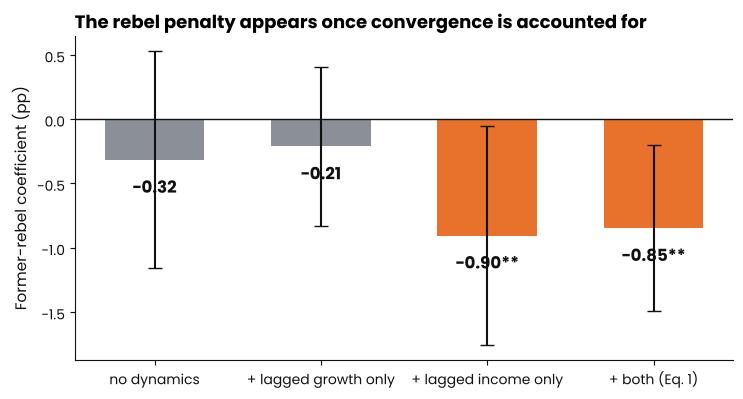

In [14]:
base_X = TRAITS + LEADER_CTRL + ["lag_growth"] + INST
short = fe_ols(main, "growth", base_X, FE2)                               # without initial income
long_ = fe_ols(main, "growth", base_X + ["lag_lngdppc"], FE2)             # with initial income (= Eq. 1)
aux   = fe_ols(main, "lag_lngdppc", base_X, FE2)                           # trait -> initial income
rho, delta = long_.params["lag_lngdppc"], aux.params["rebel"]
print(f"beta_rebel without income control : {short.params['rebel']:+.3f} (SE {short.bse['rebel']:.3f})")
print(f"beta_rebel with income control    : {long_.params['rebel']:+.3f} (SE {long_.bse['rebel']:.3f})")
print(f"rho (convergence) = {rho:+.3f};  delta (rebel -> ln GDPpc(t-1), within country) = {delta:+.3f} (SE {aux.bse['rebel']:.3f})")
print(f"Identity check: {long_.params['rebel']:+.3f} + ({rho:+.3f})*({delta:+.3f}) = {long_.params['rebel'] + rho * delta:+.3f}"
      f"  vs short = {short.params['rebel']:+.3f}")
word = "poorer" if delta < 0 else "richer"
print(f"Interpretation: holding the other regressors fixed, rebels govern when the country is {abs(100 * delta):.1f} log points "
      f"{word} than usual for that country, so convergence alone predicts {rho * delta:+.2f} pp of growth. "
      f"Leaving initial income out loads that catch-up onto the rebel dummy.")
steps = {}
for lab, X in [("no dynamics", TRAITS + LEADER_CTRL + INST), ("+ lagged growth only", TRAITS + LEADER_CTRL + INST + ["lag_growth"]),
               ("+ lagged income only", TRAITS + LEADER_CTRL + INST + ["lag_lngdppc"]), ("+ both (Eq. 1)", TRAITS + LEADER_CTRL + INST + DYN)]:
    r = fe_ols(main, "growth", X, FE2); steps[lab] = {"b": float(r.params["rebel"]), "se": float(r.bse["rebel"]), "p": float(r.pvalues["rebel"])}
display(pd.DataFrame(steps).T.round(3).rename(columns={"b": "β rebel", "se": "SE", "p": "p"}))
RESULTS["ovb"] = {"short": float(short.params["rebel"]), "long": float(long_.params["rebel"]), "rho": float(rho),
                  "delta": float(delta), "delta_se": float(aux.bse["rebel"]), "bias": float(rho * delta), "steps": steps}

fig, ax = plt.subplots(figsize=(8.5, 4.2))
labs = list(steps); vals = [steps[k]["b"] for k in labs]; ses = [steps[k]["se"] for k in labs]
cols = [GREY, GREY, ORANGE, ORANGE]
ax.bar(range(4), vals, color=cols, width=0.6, yerr=[1.96 * s for s in ses], capsize=5, ecolor=INK)
for i, (v, k) in enumerate(zip(vals, labs)):
    ax.text(i, v - 0.12, f"{num(v, 2)}{stars(steps[k]['p'])}", ha="center", va="top", fontsize=12, fontweight="bold", color=INK)
ax.axhline(0, color=INK, lw=1); ax.set_xticks(range(4)); ax.set_xticklabels(labs)
ax.set_ylabel("Former-rebel coefficient (pp)")
ax.set_title("The rebel penalty appears once convergence is accounted for", loc="left")
fig.savefig(f"{OUT}/fig_ovb_steps.png"); plt.show()

**Why this matters for identification.** This is an omitted-variable problem with a known sign. Rebels come to power when their country is unusually poor relative to its own history (δ = −0.21, SE 0.04), and countries that are poor relative to their own history grow faster (ρ < 0). The bias ρ·δ = +0.64 pp hides most of the penalty. If lagged income measures initial conditions with error, part of the catch-up is still loaded onto the rebel dummy, so −0.85 is, if anything, an underestimate.

## 6. Table 4 — Heterogeneity I: institutional void vs institutional support (Eq. 2)

$$\mathrm{Growth}_{c,t} = [\mathrm{Eq.}\,1] + \mu\,\mathrm{Void}_{c,t} + \sum_{k=1}^{5}\delta_k\,(\mathrm{Trait}_{k,c,t}\times\mathrm{Void}_{c,t}) + \varepsilon_{c,t}$$

*Void* = 1 when executive constraints are 1–3. In this model β_k is the effect of trait *k* under **institutional support** and β_k + δ_k its effect in an **institutional void**; δ_k is the difference.

**Two competing predictions**
- **H2a, void amplifies** (Jones & Olken 2005; managerial discretion, Hambrick & Finkelstein 1987): with no checks, a leader's type passes straight into policy, so |β + δ| > |β| — harmful traits do more harm, helpful traits more good.
- **H2b, support complements** (Besley et al. 2011): skills need a working state to become results, so productive traits such as education matter more under support (δ < 0 for graduates).

With five interactions, one could be significant by chance (1 − 0.95⁵ ≈ 23%). The decisive statistic is the **joint F-test that all five δ are zero**. Columns (2)–(3) move the void cut-off to check the result does not hinge on xconst ≤ 3.

In [15]:
def interact(df, mod, traits=TRAITS, main_effect=True, extra_X=()):
    df = df.dropna(subset=[mod]).copy(); inter = []
    for k in traits:
        df[f"{k}_x_{mod}"] = df[k] * df[mod]; inter.append(f"{k}_x_{mod}")
    X = TRAITS + LEADER_CTRL + DYN + INST + list(extra_X) + ([mod] if main_effect else []) + inter
    return df, X, inter

def het_model(df, mod, main_effect=True, fe=FE2, extra_X=()):
    d_, X, inter = interact(df, mod, main_effect=main_effect, extra_X=extra_X)
    r = fe_ols(d_, "growth", X, fe)
    F, p = wald_test(r, inter)
    me = {k: lincom(r, {k: 1, f"{k}_x_{mod}": 1}) for k in TRAITS}
    return r, inter, F, p, me

T4, T4j, T4me = {}, {}, {}
for col, vcol in [("(1) Void: xconst ≤ 3", "void"), ("(2) Void: xconst ≤ 2", "void_le2"), ("(3) Void: xconst ≤ 4", "void_le4")]:
    df = main.assign(void=main[vcol])
    r, inter, F, p, me = het_model(df, "void")
    T4[col], T4j[col], T4me[col] = r, (F, p), me
lab4 = dict(LABELS, void="Institutional void (main effect)",
            **{f"{k}_x_void": f"{LABELS[k]} × void" for k in TRAITS})
rows = TRAITS + ["void"] + [f"{k}_x_void" for k in TRAITS]
extra = ([(f"Effect in void: {LABELS[k]}", [f"{num(T4me[c][k][0])}{stars(T4me[c][k][2])} ({T4me[c][k][1]:.3f})" for c in T4]) for k in TRAITS]
         + [("Joint test, all five δ = 0: F (p)", [f"{T4j[c][0]:.2f} ({T4j[c][1]:.3f})" for c in T4]),
            ("Controls, country and year FE", ["✓"] * 3), ("Observations", [f"{r.nobs:,}" for r in T4.values()])])
html, rec4 = reg_table(T4, rows, lab4, extra,
    title="Table 4 — Does an institutional void amplify leader effects? (Eq. 2)",
    note="Trait rows give effects under institutional support (β); '× void' rows give the difference (δ); 'Effect in void' rows "
         "give β + δ with its standard error. All columns include the Eq. 1 controls.")
display(HTML(html))
for c in T4:
    rec4[c].update(joint_F=T4j[c][0], joint_p=T4j[c][1], N=T4[c].nobs,
                   me={k: {"b": T4me[c][k][0], "se": T4me[c][k][1], "p": T4me[c][k][2]} for k in TRAITS})
RESULTS["table4"] = rec4

,(1) Void: xconst ≤ 3,(2) Void: xconst ≤ 2,(3) Void: xconst ≤ 4
Graduate degree,−0.116,−0.159,−0.120
,(0.160),(0.165),(0.155)
"Military service, no combat",0.078,−0.318,−0.010
,(0.320),(0.277),(0.311)
Combat veteran,−0.129,−0.003,−0.120
,(0.235),(0.245),(0.221)
Former rebel,−0.384,−0.557*,−0.488
,(0.330),(0.321),(0.331)
Irregular entry (coup/revolt),0.709,−1.010**,−0.360
,(0.675),(0.406),(0.632)


**Reading Table 4.** At the baseline cut-off (column 1) the five trait × void interactions are jointly significant only at 10% (F = 1.91, p = 0.095). The pattern is clear in the last column: in a void, former rebels cost 1.44 pp a year (p < 0.01) against −0.38 (n.s.) with support (δ = −1.05, p = 0.07); irregular entry costs 0.95 pp in a void (δ = −1.66, p = 0.04); combat veterans *raise* growth by 1.56 pp in a void (δ = +1.68, p = 0.03). Graduates do not matter in either regime. The result depends on where the void line is drawn: with the strictest void (xconst ≤ 2) the joint test rejects at 5% (p = 0.02); with xconst ≤ 4 it does not (p = 0.28).

**Verdict.** Partial support for H3a: in an institutional void, leader backgrounds — above all a rebel past — matter more, but the joint evidence is at the 10% level and sensitive to the cut-off. No support for H3b: graduates do not matter more under institutional support.

## 7. Table 5 — Heterogeneity II: development and state capacity (Eq. 3)

$$\mathrm{Growth}_{c,t} = [\mathrm{Eq.}\,1] + \sum_{k=1}^{5}\theta_k\,(\mathrm{Trait}_{k,c,t}\times\mathrm{Poor}_{c}) + \varepsilon_{c,t}$$

**Why look at development?** Formal constraints are one kind of "institution", but the capacity of the state to carry out decisions is another. Where the bureaucracy is thin, the head of government substitutes for missing organisations, so the leader's own skills should matter more (Besley & Persson 2011 on state capacity; Jones & Olken 2005 find leader effects concentrated in autocracies). Poverty and the institutional void overlap but are not the same: about a third of country-years are poor with strong checks or rich with weak checks.

**Three definitions of *Poor*, from most to least exogenous**
1. *Initially poor country*: income in the country's first five observed years is below the median country. Fixed for each country, so it cannot be caused by the leaders we study; its main effect is absorbed by country fixed effects.
2. *Poor at the leader's entry*: income in the year before the leader took office below the median — predetermined for that leader.
3. *Poor last year*: lagged income below the sample median — time-varying, and possibly affected by earlier leaders.

**Horse race (column 4).** Both sets of interactions enter together: trait × initially poor and trait × void. If the development dimension survives and the institutional one does not, it is development, not the formal void, that conditions leader effects.

,(1) Initially poor country,(2) Poor at leader's entry,(3) Poor last year,(4) Horse race
Graduate degree,−0.463**,−0.270,−0.444**,−0.397**
,(0.227),(0.231),(0.224),(0.193)
"Military service, no combat",0.450,−0.165,−0.069,0.153
,(0.500),(0.428),(0.452),(0.379)
Combat veteran,0.439,0.656,0.763,0.054
,(0.518),(0.605),(0.516),(0.326)
Former rebel,−0.491,−0.632,−0.895*,−0.196
,(0.476),(0.447),(0.482),(0.397)
Irregular entry (coup/revolt),−1.230,−1.349,−0.201,0.093
,(0.767),(1.022),(0.689),(0.845)


,Trait × poor: F,Trait × poor: p,Trait × void: F,Trait × void: p,Former rebel in poor country,p (rebel),Combat veteran in poor country,p (combat)
Initially poor country,1.560,0.175,1.824,0.111,-0.671,0.288,-0.314,0.673
Poor at leader's entry,2.579,0.028,2.300,0.048,-0.120,0.818,-0.830,0.218
Poor last year,2.541,0.031,2.405,0.039,0.008,0.990,-0.960,0.183


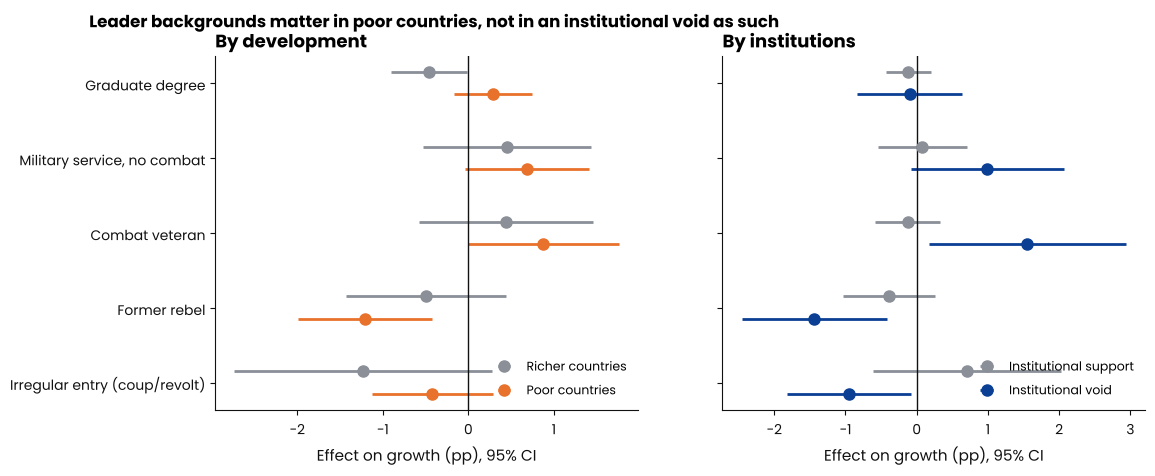

In [16]:
T5, T5j, T5me = {}, {}, {}
for col, mod, me_flag in [("(1) Initially poor country", "poor_init", False), ("(2) Poor at leader's entry", "poor_entry", True),
                          ("(3) Poor last year", "poor", True)]:
    r, inter, F, p, me = het_model(main, mod, main_effect=me_flag)
    T5[col], T5j[col], T5me[col] = r, {mod: (F, p)}, me
# horse race
hr = main.copy(); inter_all = []
for m in ["poor_init", "void"]:
    for k in TRAITS:
        hr[f"{k}_x_{m}"] = hr[k] * hr[m]; inter_all.append(f"{k}_x_{m}")
rhr = fe_ols(hr, "growth", TRAITS + LEADER_CTRL + DYN + INST + ["void"] + inter_all, FE2)
T5["(4) Horse race"] = rhr
T5j["(4) Horse race"] = {m: wald_test(rhr, [f"{k}_x_{m}" for k in TRAITS]) for m in ["poor_init", "void"]}
T5me["(4) Horse race"] = {k: lincom(rhr, {k: 1, f"{k}_x_poor_init": 1}) for k in TRAITS}

def mlabel(m):
    return {"poor_init": "initially poor", "poor_entry": "poor at entry", "poor": "poor last year", "void": "void"}[m]
lab5 = dict(LABELS, poor_entry="Poor at entry (main effect)", poor="Poor last year (main effect)", void="Institutional void (main effect)")
rows = list(TRAITS)
for m in ["poor_init", "poor_entry", "poor", "void"]:
    for k in TRAITS:
        lab5[f"{k}_x_{m}"] = f"{LABELS[k]} × {mlabel(m)}"
rows += ([f"{k}_x_{m}" for m in ["poor_init", "poor_entry", "poor"] for k in TRAITS] + [f"{k}_x_void" for k in TRAITS]
         + ["poor_entry", "poor", "void"])
cols = list(T5)
def jt(c, m):
    return f"{T5j[c][m][0]:.2f} ({T5j[c][m][1]:.3f})" if m in T5j[c] else ""
extra = ([(f"Effect in poor countries: {LABELS[k]}", [f"{num(T5me[c][k][0])}{stars(T5me[c][k][2])} ({T5me[c][k][1]:.3f})" for c in cols]) for k in TRAITS]
         + [("Joint test, trait × poor = 0: F (p)", [jt(c, "poor_init") or jt(c, "poor_entry") or jt(c, "poor") for c in cols]),
            ("Joint test, trait × void = 0: F (p)", ["", "", "", jt("(4) Horse race", "void")]),
            ("Controls, country and year FE", ["✓"] * 4), ("Observations", [f"{T5[c].nobs:,}" for c in cols])])
html, rec5 = reg_table(T5, rows, lab5, extra,
    title="Table 5 — Do leaders matter more in poor countries? (Eq. 3)",
    note="Trait rows give effects in richer countries (the reference group); '× poor' rows the difference; 'Effect in poor countries' "
         "rows the sum with its standard error. Column (1) is preferred because initial income is fixed for each country. Column (4) "
         "adds trait × void interactions at the same time.")
display(HTML(html))
for c in cols:
    rec5[c].update(N=T5[c].nobs, joint={m: {"F": v[0], "p": v[1]} for m, v in T5j[c].items()},
                   me={k: {"b": T5me[c][k][0], "se": T5me[c][k][1], "p": T5me[c][k][2]} for k in TRAITS})
RESULTS["table5"] = rec5

# Table 5B: the horse race for each definition of "poor"
hr5 = {}
for mod, lab, me_flag in [("poor_init", "Initially poor country", False), ("poor_entry", "Poor at leader's entry", True),
                          ("poor", "Poor last year", True)]:
    h = main.dropna(subset=[mod]).copy(); ip, iv = [], []
    for k in TRAITS:
        h[f"{k}_x_{mod}"] = h[k] * h[mod]; ip.append(f"{k}_x_{mod}")
        h[f"{k}_x_void"] = h[k] * h["void"]; iv.append(f"{k}_x_void")
    r = fe_ols(h, "growth", TRAITS + LEADER_CTRL + DYN + INST + ["void"] + ([mod] if me_flag else []) + ip + iv, FE2)
    (Fp, pp), (Fv, pv) = wald_test(r, ip), wald_test(r, iv)
    rp = lincom(r, {"rebel": 1, f"rebel_x_{mod}": 1}); cp = lincom(r, {"combatvet": 1, f"combatvet_x_{mod}": 1})
    hr5[lab] = {"Trait × poor: F": Fp, "Trait × poor: p": pp, "Trait × void: F": Fv, "Trait × void: p": pv,
                "Former rebel in poor country": rp[0], "p (rebel)": rp[2], "Combat veteran in poor country": cp[0], "p (combat)": cp[2]}
t5b = pd.DataFrame(hr5).T
display(t5b.style.format("{:.3f}").set_caption("Table 5B — Horse race: development vs institutional void, three definitions of 'poor'"))
RESULTS["table5b"] = hr5

# figure: marginal effects, poor vs rich (column 1) next to void vs support (Table 4, column 1)
r1, me1 = T5["(1) Initially poor country"], T5me["(1) Initially poor country"]
rv, mev = T4["(1) Void: xconst ≤ 3"], T4me["(1) Void: xconst ≤ 3"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (r, me, a_lab, b_lab, title) in zip(axes, [(r1, me1, "Richer countries", "Poor countries", "By development"),
                                                 (rv, mev, "Institutional support", "Institutional void", "By institutions")]):
    for i, k in enumerate(TRAITS[::-1]):
        ax.errorbar(r.params[k], i + 0.15, xerr=1.96 * r.bse[k], fmt="o", color=GREY, ms=8, lw=2, label=a_lab if i == 0 else None)
        ax.errorbar(me[k][0], i - 0.15, xerr=1.96 * me[k][1], fmt="o", color=ORANGE if title == "By development" else BLUE,
                    ms=8, lw=2, label=b_lab if i == 0 else None)
    ax.axvline(0, color=INK, lw=1); ax.set_title(title, loc="left"); ax.legend(frameon=False, loc="lower right", fontsize=9)
    ax.set_xlabel("Effect on growth (pp), 95% CI")
axes[0].set_yticks(range(5)); axes[0].set_yticklabels([LABELS[k] for k in TRAITS[::-1]])
fig.suptitle("Leader backgrounds matter in poor countries, not in an institutional void as such", x=0.02, ha="left", fontweight="bold")
fig.savefig(f"{OUT}/fig_heterogeneity.png"); plt.show()

**Reading Table 5.** Development tells a similar but weaker story. With the most exogenous definition (column 1, initially poor country) the trait × poor interactions are jointly significant at 10% (F = 1.96, p = 0.088). In initially poor countries, former rebels cost 1.21 pp a year (p < 0.01) and combat veterans add 0.87 pp (p = 0.05); in richer countries the rebel coefficient is −0.49 (n.s.). With the other definitions the joint test is p = 0.064 (poor at the leader's entry) and p = 0.015 (poor last year).

**The horse race** (column 4 and Table 5B) puts both sets of interactions in one regression. Neither wins: with initially poor countries, neither block is jointly significant (p = 0.18 for poverty, 0.11 for the void); with the other two definitions both blocks are (p ≈ 0.03–0.05). Poverty and weak constraints overlap so much in this sample that the data cannot say which one does the work.

**Our reading.** Leader backgrounds — above all a rebel past — matter more where states are weak, whether "weak" means few checks on the executive or a poor economy; we cannot separate the two. One unexpected result: graduate leaders in richer countries are associated with slightly lower growth (−0.46, p < 0.05), which we report but do not over-interpret.

## 8. Table 6 — Heterogeneity III: which rebels? Route to power, education, military service and era (Eq. 4)

Which rebels carry the penalty? We interact the rebel dummy with three other backgrounds, one at a time.

$$\mathrm{Growth}_{c,t} = [\mathrm{Eq.}\,1] + \pi\,(\mathrm{Rebel}\times Z)_{c,t} + \varepsilon_{c,t},\qquad Z \in \{\mathrm{Irregular\ entry},\ \mathrm{Graduate},\ \mathrm{Military\ service}\}$$

- **Rebel × Irregular** separates a rebel past (human capital acquired in rebellion) from the act of seizing power. Implied effects: rebel who seized power = β₄ + β₅ + π; rebel who entered regularly = β₄; non-rebel who seized power (e.g. a coup by officers) = β₅.
- **Rebel × Graduate** asks whether an educated rebel (the "intellectual revolutionary") costs less.
- **Rebel × Military service** asks whether rebels with formal military training (combat or not) cost more or less than guerrilla leaders without it.
- **Trait × Cold War (≤ 1989)** asks whether superpower patronage changed which leaders mattered. The Cold War dummy itself is absorbed by year fixed effects.

,(1) Rebel × irregular,(2) Rebel × graduate,(3) Rebel × military,(4) × Cold War
Graduate degree,−0.123,−0.130,−0.146,−0.383
,(0.155),(0.178),(0.158),(0.249)
"Military service, no combat",0.369,0.453,0.508,0.289
,(0.312),(0.313),(0.333),(0.434)
Combat veteran,0.636*,0.543,0.627,0.497
,(0.344),(0.351),(0.397),(0.484)
Former rebel,−0.455,−0.819**,−0.715,−0.750
,(0.315),(0.392),(0.444),(0.497)
Irregular entry (coup/revolt),0.397,−0.633*,−0.594*,−0.940
,(0.472),(0.342),(0.331),(0.584)


Country-years: rebel & seized power 919; rebel & regular entry 683


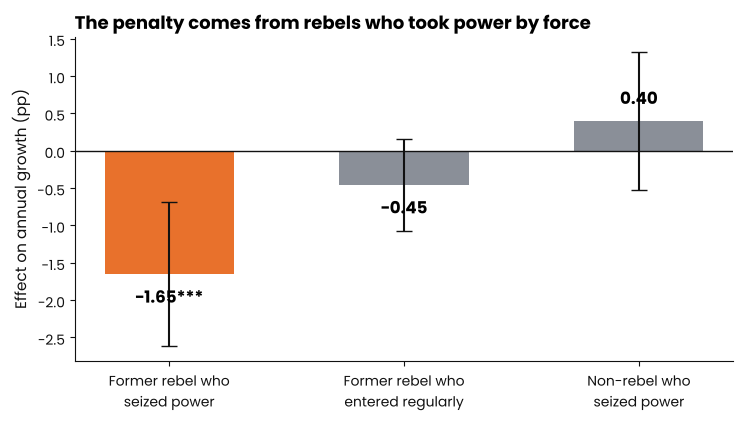

In [17]:
d6 = main.assign(rebel_x_irr=main.rebel * main.irregular_entry, rebel_x_grad=main.rebel * main.grad_edu, rebel_x_mil=main.rebel * main.milservice)
r6a = fe_ols(d6, "growth", TRAITS + LEADER_CTRL + DYN + INST + ["rebel_x_irr"], FE2)
r6b = fe_ols(d6, "growth", TRAITS + LEADER_CTRL + DYN + INST + ["rebel_x_grad"], FE2)
r6d = fe_ols(d6, "growth", TRAITS + LEADER_CTRL + DYN + INST + ["rebel_x_mil"], FE2)
cw = main.assign(coldwar=(main.year <= 1989).astype(float))
r6c, inter_c, Fc, pc, mec = het_model(cw, "coldwar", main_effect=False)
T6 = {"(1) Rebel × irregular": r6a, "(2) Rebel × graduate": r6b, "(3) Rebel × military": r6d, "(4) × Cold War": r6c}
imp = {"rebel_force": lincom(r6a, {"rebel": 1, "irregular_entry": 1, "rebel_x_irr": 1}),
       "rebel_regular": lincom(r6a, {"rebel": 1}), "coup_nonrebel": lincom(r6a, {"irregular_entry": 1})}
lab6 = dict(LABELS, rebel_x_irr="Former rebel × irregular entry", rebel_x_grad="Former rebel × graduate degree", rebel_x_mil="Former rebel × military service",
            **{f"{k}_x_coldwar": f"{LABELS[k]} × Cold War" for k in TRAITS})
rows = TRAITS + ["rebel_x_irr", "rebel_x_grad", "rebel_x_mil"] + [f"{k}_x_coldwar" for k in TRAITS]
imp.update({"rebel_grad": lincom(r6b, {"rebel": 1, "grad_edu": 1, "rebel_x_grad": 1}), "rebel_nograd": lincom(r6b, {"rebel": 1}),
            "rebel_nomil": lincom(r6d, {"rebel": 1})})
f3 = lambda t: f"{num(t[0])}{stars(t[2])} ({t[1]:.3f})"
extra = [("Rebel who seized power (β₄+β₅+π)", [f3(imp["rebel_force"]), "", "", ""]),
         ("Rebel who entered regularly (β₄)", [f3(imp["rebel_regular"]), "", "", ""]),
         ("Non-rebel who seized power (β₅)", [f3(imp["coup_nonrebel"]), "", "", ""]),
         ("Joint test, trait × Cold War = 0: F (p)", ["", "", "", f"{Fc:.2f} ({pc:.3f})"]),
         ("Controls, country and year FE", ["✓"] * 4), ("Observations", [f"{r.nobs:,}" for r in T6.values()])]
html, rec6 = reg_table(T6, rows, lab6, extra, title="Table 6 — Which rebels? Route to power, education, military service and era (Eq. 4)",
    note="All columns include the Eq. 1 controls. Military service = combat or non-combat service. Column (4): trait rows give effects after 1989; the Cold War main effect is absorbed by year fixed effects.")
display(HTML(html))
RESULTS["table6"] = rec6
RESULTS["table6"]["implied"] = {k: {"b": v[0], "se": v[1], "p": v[2]} for k, v in imp.items()}
RESULTS["table6"]["coldwar_joint"] = {"F": Fc, "p": pc}
nrf = int(((main.rebel == 1) & (main.irregular_entry == 1)).sum()); nrr = int(((main.rebel == 1) & (main.irregular_entry == 0)).sum())
print(f"Country-years: rebel & seized power {nrf:,}; rebel & regular entry {nrr:,}")
RESULTS["table6"]["counts"] = {"rebel_force": nrf, "rebel_regular": nrr,
                               "rebel_grad": int(((main.rebel == 1) & (main.grad_edu == 1)).sum()), "rebel_mil": int(((main.rebel == 1) & (main.milservice == 1)).sum())}

fig, ax = plt.subplots(figsize=(8.5, 4.2))
keys = ["rebel_force", "rebel_regular", "coup_nonrebel"]
labs = ["Former rebel who\nseized power", "Former rebel who\nentered regularly", "Non-rebel who\nseized power"]
vals = [imp[k][0] for k in keys]; ses = [imp[k][1] for k in keys]
ax.bar(range(3), vals, yerr=[1.96 * s for s in ses], color=[ORANGE, GREY, GREY], width=0.55, capsize=6, ecolor=INK)
for i, k in enumerate(keys):
    ax.text(i, vals[i] + (0.15 if vals[i] > 0 else -0.15), f"{num(vals[i], 2)}{stars(imp[k][2])}", ha="center",
            va="bottom" if vals[i] > 0 else "top", fontsize=12, fontweight="bold")
ax.axhline(0, color=INK, lw=1); ax.set_xticks(range(3)); ax.set_xticklabels(labs)
ax.set_ylabel("Effect on annual growth (pp)")
ax.set_title("The penalty comes from rebels who took power by force", loc="left")
fig.savefig(f"{OUT}/fig_rebel_route.png"); plt.show()

**Reading Table 6.** The rebel penalty is about how power was taken. A former rebel who seized power irregularly is associated with growth 1.65 pp lower per year (p < 0.01); a former rebel who came to power through regular channels, −0.45 (n.s.); a non-rebel who seized power, such as an officer in a palace coup, +0.40 (n.s.). The interaction itself is −1.59 (p = 0.01). Neither a rebel past alone nor a coup alone is enough: the cost comes from leaders who learned politics in an armed movement *and* took the state by force, consistent with evidence that revolutionary leaders take larger risks (Colgan 2013). Education and military training do not change the rebel penalty: rebel × graduate −0.08 (p = 0.87), rebel × military service −0.26 (p = 0.62), so it is the route to power, not the rebel's schooling or formal military training, that matters. Leader effects did not change after the Cold War (joint p = 0.75).

## 9. Table 7 — Reverse causality

Growth might choose the leader rather than the reverse: a slump can trigger a coup (Londregan & Poole 1990), a boom can keep an incumbent in office. Three tests, each with country and year fixed effects:

**Test 1 — does growth predict who comes to power? (Y → X)**

$$\mathrm{Trait}_{c,t} = \alpha_c + \gamma_t + \theta_1\mathrm{Growth}_{c,t-1} + \theta_2\mathrm{Growth}_{c,t-2} + \pi_1\mathrm{Trait}_{c,t-1} + \pi_2\mathrm{Trait}_{c,t-2} + u_{c,t}$$

Does past growth predict a switch to this type of leader? H₀: θ₁ = θ₂ = 0.

**Test 2 — does a change of leader type predict later growth? (X → Y, Granger)**

$$\mathrm{Growth}_{c,t} = \alpha_c + \gamma_t + \phi_1\mathrm{Growth}_{c,t-1} + \phi_2\mathrm{Growth}_{c,t-2} + \psi_1\mathrm{Trait}_{c,t-1} + \psi_2\mathrm{Trait}_{c,t-2} + e_{c,t}$$

Do past changes in leader type predict growth beyond growth's own past? H₀: ψ₁ = ψ₂ = 0. (Granger causality means predictive precedence, not proof of causation.) **Test 2b** adds lagged ln GDP per capita: Section 5.1 shows that convergence masks the rebel effect, and the textbook Granger form inherits that masking.

**Test 3 — lead test: does next year's leader "predict" this year's growth?**

$$\mathrm{Growth}_{c,t} = [\mathrm{Eq.}\,1] + \kappa\,\mathrm{Trait}_{c,t+1} + \varepsilon_{c,t}$$

Next year's leader cannot cause this year's growth, so κ should be zero. A non-zero κ would mean something that predicts the coming leader is already moving growth. Because traits barely change from one year to the next, the lead is almost the same variable as the current trait, so κ also picks up the trait's own effect. **Test 3b** isolates the pre-trend: a dummy for the year *before* a leader with the trait replaces one without it.

A non-rejection is not proof of no reverse causality; with few transitions per country these tests have limited power, which we say openly.

In [18]:
sub = panel[panel.year.between(1961, 2018)]
rows7, rec7 = [], {}
for k in TRAITS:
    a = fe_ols(sub, k, ["lag_growth", "lag2_growth", f"lag_{k}", f"lag2_{k}"], FE2); Fa, pa = wald_test(a, ["lag_growth", "lag2_growth"])
    b_ = fe_ols(sub, "growth", ["lag_growth", "lag2_growth", f"lag_{k}", f"lag2_{k}"], FE2); Fb, pb = wald_test(b_, [f"lag_{k}", f"lag2_{k}"])
    b2 = fe_ols(sub, "growth", ["lag_growth", "lag2_growth", "lag_lngdppc", f"lag_{k}", f"lag2_{k}"], FE2)
    Fb2, pb2 = wald_test(b2, [f"lag_{k}", f"lag2_{k}"]); s2 = lincom(b2, {f"lag_{k}": 1, f"lag2_{k}": 1})
    c_ = fe_ols(main, "growth", TRAITS + LEADER_CTRL + DYN + INST + [f"lead_{k}"], FE2)
    kap, kse, kp = c_.params[f"lead_{k}"], c_.bse[f"lead_{k}"], c_.pvalues[f"lead_{k}"]
    sw = main.assign(sw=((main[f"lead_{k}"] == 1) & (main[k] == 0)).astype(float).where(main[f"lead_{k}"].notna()))
    c2 = fe_ols(sw, "growth", TRAITS + LEADER_CTRL + DYN + INST + ["sw"], FE2)   # year before such a leader takes over
    swb, swse, swp = c2.params["sw"], c2.bse["sw"], c2.pvalues["sw"]
    rows7.append([LABELS[k], f"{Fa:.2f}", f"{pa:.3f}", f"{Fb:.2f}", f"{pb:.3f}", f"{Fb2:.2f}", f"{pb2:.3f}",
                  f"{num(s2[0])}{stars(s2[2])}", f"{num(kap)}{stars(kp)} ({kse:.3f})", f"{kp:.3f}", f"{num(swb)}{stars(swp)} ({swse:.3f})", f"{swp:.3f}"])
    rec7[k] = {"yx_F": Fa, "yx_p": pa, "xy_F": Fb, "xy_p": pb, "xy2_F": Fb2, "xy2_p": pb2, "xy2_sum": s2[0], "xy2_sum_se": s2[1],
               "xy2_sum_p": s2[2], "lead_b": kap, "lead_se": kse, "lead_p": kp, "sw_b": swb, "sw_se": swse, "sw_p": swp, "sw_n": int(sw.sw.sum()), "N_yx": a.nobs}
cl = fe_ols(main, "growth", TRAITS + LEADER_CTRL + DYN + INST + [f"lead_{k}" for k in TRAITS], FE2)
Fl, pl = wald_test(cl, [f"lead_{k}" for k in TRAITS])
t7 = pd.DataFrame(rows7, columns=["Trait", "1. Y→X: F", "p", "2. X→Y: F", "p ", "2b. X→Y + income: F", "p  ",
                                  "2b. ψ₁+ψ₂", "3. Lead κ (SE)", "p   ", "3b. Year before a switch (SE)", "p    "]).set_index("Trait")
display(t7.style.set_caption("Table 7 — Reverse-causality tests (1961–2018)"))
print(f"Joint lead test, all five traits: F = {Fl:.2f}, p = {pl:.3f}, N = {cl.nobs:,}")
RESULTS["table7"] = rec7; RESULTS["table7"]["joint_lead"] = {"F": Fl, "p": pl, "N": cl.nobs}

# pre-entry growth: do particular types arrive after slumps? (spell file)
sp = pd.read_csv(DATA_SPELL)
for c in ["rebel", "milservice", "grad_edu"]:
    sp[c] = pd.to_numeric(sp[c], errors="coerce").replace(-77, np.nan)
sp["irregular"] = (sp.entry_arch == "Irregular").astype(float).where(sp.entry_arch.isin(["Regular", "Irregular"]))
sp["country_id"] = sp.idacr.replace({"GMY": "GFR", "ROM": "RUM", "SRB": "YUG"})
sp["decade"] = (pd.to_numeric(sp.inyear, errors="coerce") // 10) * 10
pre = {}
for k, lab in [("rebel", "Former rebel"), ("milservice", "Military service"), ("irregular", "Irregular entry"),
               ("grad_edu", "Graduate degree")]:
    s = sp.dropna(subset=[k, "pre_entry_growth_2yr", "decade"])
    r = fe_ols(s, "pre_entry_growth_2yr", [k], ("country_id", "decade"))
    pre[lab] = {"Raw mean, with trait": s.loc[s[k] == 1, "pre_entry_growth_2yr"].mean(),
                "Raw mean, without": s.loc[s[k] == 0, "pre_entry_growth_2yr"].mean(),
                "Within-country difference": r.params[k], "SE": r.bse[k], "p": r.pvalues[k], "Spells": r.nobs}
t7b = pd.DataFrame(pre).T
display(t7b.style.format({"Raw mean, with trait": "{:.2f}", "Raw mean, without": "{:.2f}", "Within-country difference": "{:+.2f}",
        "SE": "{:.2f}", "p": "{:.3f}", "Spells": "{:,.0f}"})
        .set_caption("Table 7B — Growth in the two years before a leader takes office (spell level, country and decade FE)"))
RESULTS["pre_entry"] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in pre.items()}

,1. Y→X: F,p,2. X→Y: F,p,2b. X→Y + income: F,p,2b. ψ₁+ψ₂,3. Lead κ (SE),p,3b. Year before a switch (SE),p
Trait,,,,,,,,,,,
Graduate degree,0.60,0.550,0.87,0.422,1.03,0.360,−0.035,−0.030 (0.235),0.899,−0.388 (0.361),0.285
"Military service, no combat",1.12,0.330,0.03,0.969,0.81,0.446,0.302,0.099 (0.437),0.821,−0.715 (0.503),0.157
Combat veteran,0.20,0.818,0.47,0.628,0.13,0.883,−0.010,−0.595* (0.346),0.087,−1.884*** (0.460),0.000
Former rebel,0.15,0.865,0.27,0.762,0.94,0.392,−0.302,−0.879** (0.364),0.017,−1.949*** (0.543),0.000
Irregular entry (coup/revolt),0.14,0.870,0.49,0.616,0.80,0.452,−0.299,−0.888** (0.421),0.037,−2.346*** (0.557),0.000


Joint lead test, all five traits: F = 1.56, p = 0.173, N = 5,268


,"Raw mean, with trait","Raw mean, without",Within-country difference,SE,p,Spells
Former rebel,3.56,3.09,+0.15,0.47,0.754,"1,388"
Military service,3.98,2.90,+0.78,0.30,0.010,"1,214"
Irregular entry,3.57,3.20,+0.53,0.53,0.324,953
Graduate degree,2.85,3.49,-0.22,0.25,0.391,"1,371"


**Reading Table 7.** Past growth does not predict a switch to any leader type (Test 1, p = 0.33–0.87), and lagged changes in leader type do not Granger-predict growth (Tests 2 and 2b). The lead test (Test 3) is the warning sign: next year's former rebel (−0.88, p = 0.02) and next year's irregular entry (−0.89, p = 0.04) are associated with lower growth this year (joint p = 0.17). Test 3b shows where this comes from: in the single year *before* a former rebel, a combat veteran or a coup leader replaces someone without that background, growth is about 2 pp lower (p < 0.01). These leaders take over in crisis years.

What this does and does not threaten. The crisis year belongs to the outgoing leader, so it does not enter the rebel coefficient directly; Eq. 1 then controls for the low lagged growth and income it leaves behind. Two checks confirm the penalty is not transition turmoil: dropping the first and last year of every spell gives −0.97 (p = 0.04), and, within countries, growth over the two years before a rebel takes office is normal (+0.15 pp, p = 0.75; Table 7B). Military leaders take office after above-normal growth (+0.78 pp, p = 0.01). **Caveat:** we cannot rule out that whatever causes the crisis also shapes growth under the new leader; the estimates are associations within countries, not experiments.

## 10. Table 8 — Robustness

Each row changes one thing and re-estimates Eq. 1. A result we put on a policy slide must keep its sign and roughly its size across these rows.

| Check | What it guards against |
|---|---|
| Region × year fixed effects | Regional shocks (Latin American debt crisis, African commodity cycles) coinciding with leader types |
| Drop transition years | Years shared by two leaders, where the trait is measured with error |
| Per-capita growth | Results driven by population growth |
| Raw (non-winsorised) growth | Winsorising trims crisis years, where leaders may matter most |
| Spells with ≥ 3 years | Very short spells, where one year's shock dominates |
| Country-specific linear trends | Slow-moving within-country trends (a demanding test that removes much of the variation) |
| Two-way clustering (country and year) | Correlation of errors across countries within a year |
| Drop first and last year of every spell | Turmoil around transitions (the year before a new leader takes over) |
| Full panel 1961–2025 without xconst | Adds our hand-coded leaders after 2004 |
| Drop one region at a time | One region driving the result |

,coef,se,p,N
check,,,,
Baseline (Eq. 1),−0.846**,0.329,0.011,"5,465"
Region × year fixed effects,−0.751**,0.323,0.021,"5,256"
Drop transition years,−0.772**,0.384,0.046,"4,759"
Per-capita growth,−1.323***,0.420,0.002,"5,465"
Raw (non-winsorised) growth,−1.166***,0.424,0.007,"5,465"
Spells with ≥ 3 years,−1.049***,0.367,0.005,"5,028"
Country-specific linear trends,−0.691**,0.348,0.049,"5,465"
Two-way clustering (country and year),−0.846***,0.306,0.008,"5,465"
Drop first and last year of every spell,−0.973**,0.459,0.036,"3,712"


,Joint p: trait × initially poor,"Former rebel, initially poor",p,"Combat veteran, initially poor",p,Rebel who seized power,p,N
check,,,,,,,,
Baseline,0.088,-1.209,0.003,0.875,0.054,-1.650,0.001,"5,465"
Region × year FE,0.039,-1.228,0.002,1.233,0.009,-1.550,0.003,"5,256"
Drop transition years,0.081,-1.152,0.012,0.696,0.133,-1.632,0.004,"4,759"
"Full panel 1961–2025, no xconst",0.030,-1.129,0.001,0.649,0.062,-1.307,0.002,"6,065"


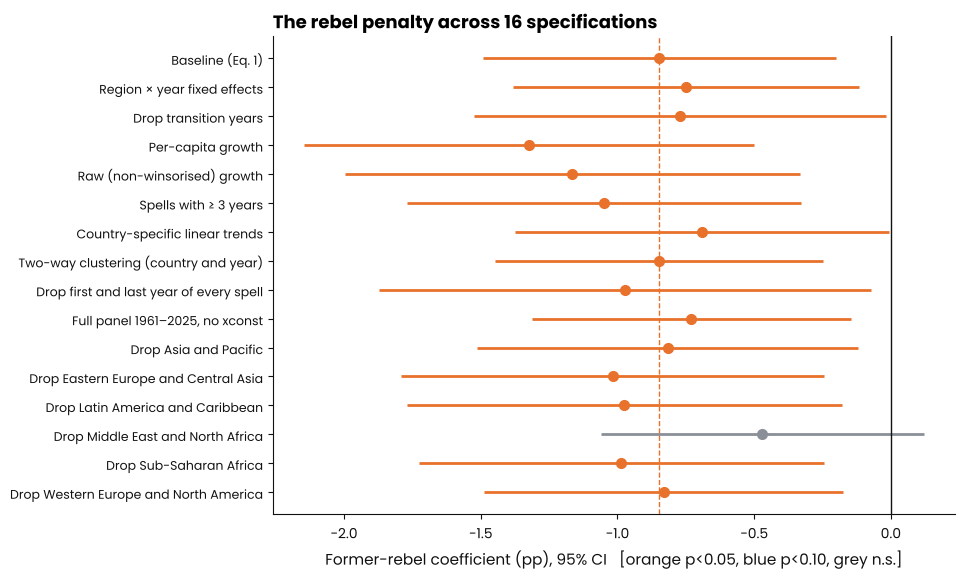

In [19]:
def rebel_row(r, label, se=None, df=None):
    s = r.bse["rebel"] if se is None else se
    t = r.params["rebel"] / s; p = float(2 * stats.t.sf(abs(t), r.df_t if df is None else df))
    return {"check": label, "b": float(r.params["rebel"]), "se": float(s), "p": p, "N": r.nobs}

X1 = TRAITS + LEADER_CTRL + DYN + INST
rob = [rebel_row(T3["(4)"], "Baseline (Eq. 1)")]
rob.append(rebel_row(T3["(6)"], "Region × year fixed effects"))
rob.append(rebel_row(fe_ols(main[main.transition == 0], "growth", X1, FE2), "Drop transition years"))
rob.append(rebel_row(fe_ols(main, "growth_pc", X1, FE2), "Per-capita growth"))
rob.append(rebel_row(fe_ols(main, "growth_raw", X1, FE2), "Raw (non-winsorised) growth"))
rob.append(rebel_row(fe_ols(main[main.groupby("spell_id").year.transform("count") >= 3], "growth", X1, FE2), "Spells with ≥ 3 years"))
tr = main.copy(); tt = (tr.year - 1980).to_numpy()
trend = pd.get_dummies(tr.country_id, dtype=float).mul(tt, axis=0); trend.columns = [f"tr_{c}" for c in trend.columns]
tr = pd.concat([tr, trend], axis=1)
rob.append(rebel_row(fe_ols(tr, "growth", X1 + list(trend.columns[1:]), FE2), "Country-specific linear trends"))
rc = T3["(4)"]; rt = fe_ols(main, "growth", X1, FE2, cluster="year")
rct = fe_ols(main.assign(cy=main.country_id + main.year.astype(str)), "growth", X1, FE2, cluster="cy")
se2 = float(np.sqrt(rc.cov.loc["rebel", "rebel"] + rt.cov.loc["rebel", "rebel"] - rct.cov.loc["rebel", "rebel"]))
rob.append(rebel_row(rc, "Two-way clustering (country and year)", se=se2, df=min(rc.G, rt.G) - 1))
edge = main.groupby("spell_id").year.transform("min").eq(main.year) | main.groupby("spell_id").year.transform("max").eq(main.year)
rob.append(rebel_row(fe_ols(main[~edge], "growth", X1, FE2), "Drop first and last year of every spell"))
rob.append(rebel_row(fe_ols(full, "growth", TRAITS + LEADER_CTRL + DYN, FE2), "Full panel 1961–2025, no xconst"))
for reg in sorted(main.region.dropna().unique()):
    rob.append(rebel_row(fe_ols(main[main.region != reg], "growth", X1, FE2), f"Drop {reg}"))
t8 = pd.DataFrame(rob).set_index("check")
t8["coef"] = [f"{num(b)}{stars(p)}" for b, p in zip(t8.b, t8.p)]
display(t8[["coef", "se", "p", "N"]].style.format({"se": "{:.3f}", "p": "{:.3f}", "N": "{:,}"})
        .set_caption("Table 8A — Robustness of the former-rebel coefficient"))
RESULTS["table8"] = rob

# robustness of the two heterogeneity results
het_rob = []
for lab, df, fe, X in [("Baseline", main, FE2, None), ("Region × year FE", ry(main.dropna(subset=["region"])), ("country_id", "region_year"), None),
                       ("Drop transition years", main[main.transition == 0], FE2, None),
                       ("Full panel 1961–2025, no xconst", full, FE2, TRAITS + LEADER_CTRL + DYN)]:
    d_, Xh, inter = interact(df, "poor_init", main_effect=False)
    if X is not None:
        Xh = X + inter
    r = fe_ols(d_, "growth", Xh, fe); F, p = wald_test(r, inter)
    me_reb = lincom(r, {"rebel": 1, "rebel_x_poor_init": 1}); me_com = lincom(r, {"combatvet": 1, "combatvet_x_poor_init": 1})
    d2 = df.assign(rebel_x_irr=df.rebel * df.irregular_entry)
    X2 = (X or X1) + ["rebel_x_irr"]
    r2 = fe_ols(d2, "growth", X2, fe); rf = lincom(r2, {"rebel": 1, "irregular_entry": 1, "rebel_x_irr": 1})
    het_rob.append({"check": lab, "joint_p_poor": p, "rebel_poor": me_reb[0], "rebel_poor_p": me_reb[2],
                    "combat_poor": me_com[0], "combat_poor_p": me_com[2], "rebel_force": rf[0], "rebel_force_p": rf[2], "N": r.nobs})
t8b = pd.DataFrame(het_rob).set_index("check")
t8b.columns = ["Joint p: trait × initially poor", "Former rebel, initially poor", "p", "Combat veteran, initially poor", "p ",
               "Rebel who seized power", "p  ", "N"]
display(t8b.style.format({**{c: "{:.3f}" for c in t8b.columns[:-1]}, "N": "{:,.0f}"})
        .set_caption("Table 8B — Robustness of the heterogeneity results"))
RESULTS["table8b"] = het_rob

fig, ax = plt.subplots(figsize=(8.8, 6.2))
yy = np.arange(len(rob))[::-1]
for y_, row in zip(yy, rob):
    c = ORANGE if row["p"] < 0.05 else (BLUE if row["p"] < 0.10 else GREY)
    ax.errorbar(row["b"], y_, xerr=1.96 * row["se"], fmt="o", color=c, ms=7, lw=2)
ax.axvline(0, color=INK, lw=1); ax.axvline(rob[0]["b"], color=ORANGE, lw=1, ls="--")
ax.set_yticks(yy); ax.set_yticklabels([r["check"] for r in rob], fontsize=9)
ax.set_xlabel("Former-rebel coefficient (pp), 95% CI   [orange p<0.05, blue p<0.10, grey n.s.]")
ax.set_title(f"The rebel penalty across {len(rob)} specifications", loc="left")
fig.savefig(f"{OUT}/fig_robustness.png"); plt.show()

**Reading Table 8.** The rebel penalty keeps its sign in all 16 specifications and is significant at 5% in 15. It is larger for per-capita growth (−1.32, p < 0.01), raw growth (−1.17, p < 0.01), longer spells (−1.05) and without the first and last year of each spell (−0.97). It holds with country-specific trends (−0.69, p = 0.049). It loses significance in one place, which we report rather than hide: dropping the Middle East and North Africa (−0.47, p = 0.12), which tells us that the region's revolutionary regimes supply much of the identifying variation. Table 8B shows that the heterogeneity results — rebels cost more in initially poor countries, and rebels who seized power cost more — survive region × year effects, dropping transition years, and the full 1961–2025 panel.

## 11. Table 9 — A second outcome: growth volatility

The mid-semester deck suggested "educated leaders buy stability", based on a raw cross-country comparison. Here we test it within countries: for each spell with at least four years in the main sample we compute the standard deviation of growth and regress it on the traits with country and decade-of-entry fixed effects.

In [20]:
spv = (main.groupby("spell_id").agg(country_id=("country_id", "first"), start=("year", "min"), n=("growth", "size"),
       sd=("growth", "std"), **{k: (k, "first") for k in TRAITS + LEADER_CTRL}).reset_index())
spv = spv[spv.n >= 4].assign(decade=lambda x: (x.start // 10) * 10)
r9 = fe_ols(spv, "sd", TRAITS + LEADER_CTRL, ("country_id", "decade"))
html, rec9 = reg_table({"SD of growth within spell": r9}, ["const"] + TRAITS + LEADER_CTRL, LABELS,
    [("Country FE, decade-of-entry FE", ["✓"]), ("Leadership spells", [f"{r9.nobs:,}"]), ("R²", [f"{r9.r2:.3f}"])],
    title="Table 9 — Do leader backgrounds predict growth volatility within countries?",
    note="One observation per spell with at least four years in the main sample. Standard errors clustered by country.")
display(HTML(html))
F9, p9 = wald_test(r9, TRAITS)
print(f"Joint test, all five traits = 0: F = {F9:.2f}, p = {p9:.3f}")
RESULTS["table9"] = rec9; RESULTS["table9"]["joint"] = {"F": F9, "p": p9, "N": r9.nobs}

,SD of growth within spell
Constant (β₀),3.118***
,(0.178)
Graduate degree,0.173
,(0.250)
"Military service, no combat",0.374
,(0.388)
Combat veteran,−0.130
,(0.340)
Former rebel,0.502
,(0.402)


Joint test, all five traits = 0: F = 1.03, p = 0.401


**Reading Table 9.** Within countries, no background predicts the volatility of growth during a spell (joint p = 0.40). The mid-semester claim that "educated leaders buy stability" came from a cross-country comparison and does not survive country fixed effects.

## 12. Export for the slides

Writes `outputs/results.json` (every number used in the deck), the figures, and the regression tables as HTML. The deck's regression tables are typed from this file only.

In [21]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    return o
with open(f"{OUT}/results.json", "w") as f:
    json.dump(clean(RESULTS), f, indent=1)
print("Saved:", sorted(os.listdir(OUT)))

Saved: ['fig_eda_decades.png', 'fig_heterogeneity.png', 'fig_main_coefplot.png', 'fig_ovb_steps.png', 'fig_placebo_leaders.png', 'fig_rebel_route.png', 'fig_robustness.png', 'placebo_F.csv', 'results.json', 'table1_summary.csv']


## 13. Summary of findings

1. **RQ1 — Do leaders matter?** The classical leader-fixed-effects test cannot separate leaders from persistence: leaders add explanatory power (F ≈ 2), but fake leaders with the same tenure lengths do just as well (permutation p = 0.88; Table 2).
2. **RQ2 — Do backgrounds matter?** One does. Former rebels are associated with growth 0.85 pp lower per year within the same country (p = 0.01), about 6.5% of GDP over an average rebel spell. Education, military service and combat have no significant average effect; irregular entry is negative at 10% (Table 3).
3. **Convergence hides the rebel penalty** in the raw data: rebels govern when their country is poor relative to its own history (Section 5.1).
4. **How power was taken matters**: the penalty is concentrated among rebels who seized power irregularly (−1.65 pp, p < 0.01; Table 6).
5. **RQ3 — Does the void amplify?** Partly. In an institutional void the rebel penalty is −1.44 pp against −0.38 with support, and the five void interactions are jointly significant at 10% (p = 0.095; p = 0.02 at the strictest cut-off). Poverty shows a similar pattern (p = 0.088), and a horse race cannot separate the two (Tables 4, 5, 5B).
6. **Reverse causality**: growth does not predict who takes over, but rebels, combat veterans and coup leaders take over in crisis years (growth about 2 pp lower the year before). The penalty survives dropping the first and last year of every spell (Table 7, Table 8).
7. **Robustness**: significant at 5% in 15 of 16 specifications; weaker without the Middle East and North Africa (Table 8).
8. **No background predicts volatility** within countries (Table 9).